# Model figures: the band-token transformer, one piece at a time

Teaching figures for the from-scratch band-token transformer in `src/sw/models/transformer.py` (DATA 255 Group 1). They run against branch `wp6-harness-gates` (SpatialPE, SpatialBlock and DropPath, SegHead, and the harness gates that log training-set metrics), last executed at commit `3ffa796`. "PR *n*" below is the WP6 pull-request stack: PR 1 SpatialPE, PR 2 SpatialBlock, PR 3 SegHead, then the planned PR 4 (full-resolution spectral skip), PR 5 (stochastic-depth schedule), PR 6 (collapsed-tokenizer control) and PR 9 (memory).

| Fig | PR | What it shows | Needs |
|---|---|---|---|
| F1 | 1 | the 2D sin-cos table, and which grid sites have similar codes | nothing |
| F2 | 2 | where three query patches attend in spatial block 1 | nothing (real cube with `SW_ROOT`, trained column with `CKPT`) |
| F3 | 3 | one token poked: how far it reaches in the head's output | nothing |
| F4 | 4 (planned) | IoU bound for a patch-constant predictor on thin lines | nothing; the skip crop waits for PR 4 |
| F5 | 5 (planned) | DropPath masks under the planned schedule; the mean is kept | nothing |
| F6 | 6 | shuffle the 14 band groups: how much do the logits move | nothing; the collapsed row waits for PR 6 |
| F7 | design | "what shape" vs "which band" on two synthetic tasks | nothing; about a minute of CPU |
| F8 | 9 | attention memory against token count, closed form and measured | nothing |
| F9 | runs | loss and mIoU curves, per-class IoU, from `metrics.jsonl` | `TRAIN_LOG` |
| F10 | trained | spectral attention across band groups, per object class | `CKPT` and `SW_ROOT` |

Every cell that needs data, a checkpoint or a log prints one `SKIP` line and moves on. Nothing here is a trained result unless a cell says it loaded `CKPT` or `TRAIN_LOG`. Numbers quoted in the text come from this notebook's own output, unless they are marked *measured elsewhere*.

## Setup

Runs in Colab and locally.

* **Colab** clones `BRANCH` (default `wp6-harness-gates`) and installs `requirements.txt`. **The branch has to be pushed to GitHub first.** `main` does not have the spatial blocks or the head yet, so until the branch is pushed the notebook runs only locally. Set `MOUNT_DRIVE = True` when the cubes, checkpoint or log live on Drive.
* **Locally** the repo is `REPO_ROOT` if that environment variable is set, otherwise the first parent folder that holds `src/sw/` (so it works from the repo root or from `notebooks/`).

Optional inputs, all environment variables (or edit the cell): `SW_ROOT` (the folder with `hyper/` and `labels_hyper_lt/`), `CKPT` (a `best.pt` or `last.pt` written by `python -m sw.train --model transformer`), `TRAIN_LOG` (a `metrics.jsonl` from the same harness; several paths can be joined with commas), `FIG_DIR` (default `docs/figures/model`) and `F7_STEPS` (default 300).

In [1]:
import os
import random
import subprocess
import sys
import time
from pathlib import Path

T_START = time.time()
BRANCH = os.environ.get("SW_BRANCH", "wp6-harness-gates")  # must be on GitHub before Colab can clone it
MOUNT_DRIVE = False  # True: mount Google Drive so SW_ROOT, CKPT and TRAIN_LOG can point into it
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if MOUNT_DRIVE:
        from google.colab import drive

        drive.mount("/content/drive")
    REPO = Path("/content/255-final-project")
    if not REPO.is_dir():
        url = "https://github.com/scottn66/255-final-project.git"
        try:
            subprocess.check_call(["git", "clone", "-q", "-b", BRANCH, url, str(REPO)])
        except subprocess.CalledProcessError as err:
            raise RuntimeError(f"could not clone branch {BRANCH!r}: push it to GitHub first, or set SW_BRANCH=main") from err
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", str(REPO / "requirements.txt")])
else:

    def _find_repo_root():
        env = os.environ.get("REPO_ROOT", "").strip()
        if env:
            return Path(env).expanduser().resolve()
        here = Path.cwd().resolve()
        for cand in [here, *here.parents]:
            if (cand / "src" / "sw" / "__init__.py").is_file():
                return cand
        raise RuntimeError("Set REPO_ROOT, or start Jupyter from the repo root or from notebooks/.")

    REPO = _find_repo_root()

if not (REPO / "src" / "sw" / "models" / "transformer.py").is_file():
    raise RuntimeError(f"{REPO} has no src/sw/models/transformer.py; is this the right branch?")
if str(REPO / "src") not in sys.path:
    sys.path.insert(0, str(REPO / "src"))


def _env_paths(name):
    raw = os.environ.get(name, "").strip()
    return [Path(p.strip()).expanduser() for p in raw.split(",") if p.strip()]


def _existing(name, kind):
    paths = _env_paths(name)
    keep = [p for p in paths if (p.is_dir() if kind == "dir" else p.is_file())]
    for p in paths:
        if p not in keep:
            print(f"{name}: {p} is not an existing {kind}; ignoring it")
    return keep


SW_ROOT = (_existing("SW_ROOT", "dir") or [None])[0]
CKPT = (_existing("CKPT", "file") or [None])[0]
TRAIN_LOGS = _existing("TRAIN_LOG", "file")
FIG_DIR = (_env_paths("FIG_DIR") or [REPO / "docs" / "figures" / "model"])[0]
FIG_DIR.mkdir(parents=True, exist_ok=True)
F7_STEPS = int(os.environ.get("F7_STEPS", "300"))
SEED = 0

import numpy as np
import torch


def seed_everything(seed=SEED):
    """Python, NumPy and torch (CPU and CUDA). Each figure cell calls it, so cells can run in any order."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"repo      {REPO}")
print(f"figures   {FIG_DIR}")
print(f"torch     {torch.__version__} on {DEVICE}")
print(f"SW_ROOT   {SW_ROOT or 'not set: F2 uses a synthetic scene, F10 skips'}")
print(f"CKPT      {CKPT or 'not set: no trained columns, F10 skips'}")
print(f"TRAIN_LOG {', '.join(map(str, TRAIN_LOGS)) or 'not set: F9 skips'}")
print(f"F7_STEPS  {F7_STEPS}")

repo      <repo>
figures   docs/figures/model
torch     2.15.0 on cpu
SW_ROOT   not set: F2 uses a synthetic scene, F10 skips
CKPT      not set: no trained columns, F10 skips
TRAIN_LOG not set: F9 skips
F7_STEPS  300


### House style

The conventions of `04_checkup_figures.ipynb`: the dataset palette for classes (`sw.data.PALETTE`, with an ink halo for the light colours), 8 pt or larger type, and figures drawn at the size of their deck slot (`SLOT_BAND` is 9.28 by 3.90 in, `SLOT_CHART` 4.37 by 3.86 in) and saved at exactly that size. Colour maps are colourblind-safe: `viridis` for sequential values, `PuOr_r` for values around a centre, and Okabe-Ito blue and vermillion for two series that are not classes.

In [2]:
import json
import math

import matplotlib.pyplot as plt
import torch.nn.functional as F
from IPython.display import Image, display
from matplotlib.colors import LogNorm, Normalize
from matplotlib.patches import Patch, Rectangle

from sw.data import CLASS_NAMES, PALETTE, SpectralWasteDataset
from sw.models.transformer import BandTransformer, DropPath, SegHead, SpatialBlock, SpatialPE, SpectralBlock
from sw.train import prepare_sample

OBJECT_CLASSES = CLASS_NAMES[1:]  # film .. bag, ids 1..6
COLOR = {name: np.array(rgb) / 255 for name, rgb in zip(CLASS_NAMES, PALETTE)}
LABEL = {**{name: name for name in CLASS_NAMES}, "video_tape": "tape"}
INK, MUTED, PAPER_FACE, GRID = "#222222", "#5c5c5c", "#f3f3f3", "#ececec"
CARD_EDGE = "#e2dbd0"  # the deck's card border
SLOT_CHART = (4.37, 3.86)  # slide 7 style: the box beside a text card
SLOT_BAND = (9.28, 3.90)  # a figure slide: the content band under the title
SEQ, DIV = "viridis", "PuOr_r"  # colourblind-safe sequential and diverging maps
C_A, C_B = "#0072B2", "#D55E00"  # Okabe-Ito blue and vermillion, for two series that are not classes

N_BANDS, GROUP, N_GROUPS, PATCH = 224, 16, 14, 8
FALSE_COLOUR_BANDS = (56, 112, 168)  # notebook 01: C // 4, C // 2, 3C // 4

plt.rcParams.update(
    {
        "font.size": 10,
        "axes.titlesize": 10,
        "axes.labelsize": 9.5,
        "xtick.labelsize": 8.5,
        "ytick.labelsize": 8.5,
        "legend.fontsize": 8.5,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "savefig.dpi": 200,
        "savefig.bbox": None,  # saved at exactly figsize, so it drops into its slot 1:1
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "image.interpolation": "nearest",
    }
)


def save(fig, name):
    """Write FIG_DIR/<name>.png at exactly its figsize, show it inline, and close the figure."""
    png = FIG_DIR / f"{name}.png"
    fig.patch.set_linewidth(2)
    fig.savefig(png, facecolor="white", edgecolor=CARD_EDGE)
    plt.close(fig)
    print("saved", png)
    display(Image(filename=str(png), width=int(fig.get_figwidth() * 100)))


def ax_in(fig, left, bottom, width, height):
    """add_axes in inches from the lower-left corner, so layouts do not depend on the figure's aspect."""
    fw, fh = fig.get_size_inches()
    return fig.add_axes([left / fw, bottom / fh, width / fw, height / fh])


def frame(ax, color="#9a9a9a"):
    """All four spines on an image panel (the style turns top and right off for charts)."""
    for side in ax.spines.values():
        side.set_visible(True)
        side.set_color(color)
        side.set_linewidth(0.6)


def plain_log_ticks(axis):
    """Log-axis tick labels as plain numbers (0.01, 1, 100) instead of powers of ten."""
    from matplotlib.ticker import FuncFormatter

    axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))


def skip(fig_id, reason):
    print(f"SKIP {fig_id}: {reason}")


def fig_title(fig, title, sub=None, y=0.975):
    fig.text(0.012, y, title, ha="left", va="top", fontsize=11, fontweight="bold", color=INK)
    if sub:
        fig.text(0.012, y - 0.062, sub, ha="left", va="top", fontsize=9, color=MUTED)


def nominal_nm(band):
    """Nominal wavelength. meta.json ships none; assume even spacing of 224 bands over 900-1700 nm."""
    return 900 + np.asarray(band, dtype=float) * 800 / (N_BANDS - 1)


def group_nm(g):
    """Nominal centre of band group g (bands 16 g .. 16 g + 15)."""
    return nominal_nm(GROUP * np.asarray(g, dtype=float) + (GROUP - 1) / 2)


def false_colour(cube):
    """(C, H, W) -> (H, W, 3) from three bands, each stretched between its 2nd and 98th percentile."""
    rgb = np.stack([cube[b] for b in FALSE_COLOUR_BANDS], axis=-1).astype(np.float64)
    for k in range(3):
        lo, hi = np.percentile(rgb[..., k], [2, 98])
        rgb[..., k] = np.clip((rgb[..., k] - lo) / (hi - lo + 1e-9), 0, 1)
    return rgb


def outline(ax, mask, lw=0.9):
    """Class outlines in the palette colour over a dark halo."""
    for c in range(1, len(CLASS_NAMES)):
        if (mask == c).any():
            m = (mask == c).astype(float)
            ax.contour(m, levels=[0.5], colors=[INK], linewidths=lw + 1.0)
            ax.contour(m, levels=[0.5], colors=[COLOR[CLASS_NAMES[c]]], linewidths=lw)


def synthetic_scene(seed=SEED, size=256):
    """A made-up 224-band scene in [0, 1]: background plus all six object classes, each with
    a smooth spectrum of its own. NOT SpectralWaste data; it only gives the init figures an input."""
    rng = np.random.default_rng(seed)
    bands = np.arange(N_BANDS)
    spectra = []
    for _ in CLASS_NAMES:
        curve = np.full(N_BANDS, rng.uniform(0.25, 0.55)) + rng.uniform(-0.12, 0.12) * (bands / N_BANDS - 0.5)
        for _ in range(3):  # a few dips and bumps
            centre, width, depth = rng.uniform(10, 214), rng.uniform(6, 25), rng.uniform(-0.18, 0.12)
            curve += depth * np.exp(-0.5 * ((bands - centre) / width) ** 2)
        spectra.append(np.clip(curve, 0.03, 0.95))
    spectra = np.stack(spectra).astype(np.float32)
    yy, xx = np.mgrid[0:size, 0:size].astype(np.float32) / size
    mask = np.zeros((size, size), np.int64)
    mask[((yy - 0.30) / 0.17) ** 2 + ((xx - 0.30) / 0.22) ** 2 < 1] = 6  # bag
    mask[(yy > 0.58) & (yy < 0.88) & (xx > 0.10) & (xx < 0.46)] = 3  # cardboard
    mask[((yy - 0.74) / 0.12) ** 2 + ((xx - 0.80) / 0.14) ** 2 < 1] = 1  # film
    mask[(yy > 0.10) & (yy < 0.38) & (xx > 0.64) & (xx < 0.90)] = 2  # basket
    mask[(np.abs(yy - 0.50 - 0.20 * (xx - 0.5)) < 1.0 / size) & (xx > 0.05) & (xx < 0.95)] = 5  # filament, 2 px
    mask[(np.abs(xx - 0.56 - 0.25 * (yy - 0.7)) < 1.5 / size) & (yy > 0.55) & (yy < 0.97)] = 4  # tape, 3 px
    shade = 1 + 0.12 * np.sin(5.0 * xx + 1.0) * np.cos(4.0 * yy)  # smooth illumination
    noise = rng.standard_normal((N_BANDS, size, size), dtype=np.float32)
    cube = spectra[mask].transpose(2, 0, 1) * shade[None] + 0.01 * noise
    return np.clip(cube, 0, 1).astype(np.float32), mask


def load_mask(path):
    from PIL import Image as PILImage

    with PILImage.open(path) as img:
        return np.array(img)


_VAL_EXAMPLE = {}


def val_example():
    """The val cube with filament and the most classes (earliest stem on ties), or None without SW_ROOT."""
    if SW_ROOT is None:
        return None
    if "x" not in _VAL_EXAMPLE:
        try:
            ds = SpectralWasteDataset(SW_ROOT, split="val")
        except (FileNotFoundError, ValueError) as err:
            print(f"SW_ROOT has no usable val split ({err}); using the synthetic scene")
            _VAL_EXAMPLE["x"] = None
            return None
        best = None
        for index, (_, mask_path) in enumerate(ds.pairs):
            ids = set(np.unique(load_mask(mask_path)).tolist())
            key = (5 in ids, len(ids), -index)
            if best is None or key > best[0]:
                best = (key, index)
        cube, mask = ds[best[1]]
        _VAL_EXAMPLE["x"] = (cube.numpy(), mask.numpy(), ds.pairs[best[1]][0].stem)
    return _VAL_EXAMPLE["x"]


_CKPT = {}


def load_ckpt():
    """(state_dict, cfg, metadata) from CKPT, or None. cfg is the TrainConfig dict sw.train saves."""
    if CKPT is None:
        return None
    if "x" not in _CKPT:
        try:
            blob = torch.load(CKPT, map_location="cpu", weights_only=True)
        except Exception:  # older torch, or extra objects in the file; it is our own sw.train output
            blob = torch.load(CKPT, map_location="cpu", weights_only=False)
        state = blob["model"] if isinstance(blob, dict) and "model" in blob else blob
        cfg = dict(blob.get("cfg") or {}) if isinstance(blob, dict) else {}
        if cfg.get("model", "transformer") != "transformer":
            raise ValueError(f"{CKPT} is a {cfg.get('model')!r} checkpoint, not a BandTransformer")
        meta = {k: blob.get(k) for k in ("epoch", "val_fg_miou", "best_val_fg_miou", "best_epoch")} if isinstance(blob, dict) else {}
        _CKPT["x"] = (state, cfg, meta)
    return _CKPT["x"]


def build_transformer(cfg=None):
    """A BandTransformer with the sizes in a sw.train cfg dict (recipe defaults when cfg is None)."""
    cfg = cfg or {}
    return BandTransformer(
        depth_spectral=int(cfg.get("depth_spectral", 2)),
        depth_spatial=int(cfg.get("depth_spatial", 6)),
        dim=int(cfg.get("dim", 64)),
        heads=int(cfg.get("heads", 4)),
        mlp_ratio=float(cfg.get("mlp_ratio", 4.0)),
        num_classes=len(CLASS_NAMES),
        n_bands=N_BANDS,
        group=int(cfg.get("group", GROUP)),
        patch=int(cfg.get("patch", PATCH)),
    )


def trained_model():
    """The CKPT weights in a model, in eval mode, or None."""
    loaded = load_ckpt()
    if loaded is None:
        return None
    state, cfg, meta = loaded
    model = build_transformer(cfg)
    model.load_state_dict(state)
    if meta.get("val_fg_miou") is not None:  # best.pt
        score = f"val FG mIoU {meta['val_fg_miou']:.4f}"
    elif meta.get("best_val_fg_miou") is not None:  # last.pt
        score = f"best val FG mIoU so far {meta['best_val_fg_miou']:.4f} (epoch {meta.get('best_epoch')})"
    else:
        score = "no val score stored"
    print(f"loaded {CKPT.name}: epoch {meta.get('epoch')}, {score}, downsample {cfg.get('downsample', 1)}")
    return model.eval()


def patch_labels(mask, patch, h, w):
    """Majority class and its share for each patch of the h x w grid, row-major like the tokenizer."""
    m = mask[: h * patch, : w * patch].reshape(h, patch, w, patch).transpose(0, 2, 1, 3).reshape(h * w, patch * patch)
    counts = np.stack([(m == c).sum(1) for c in range(len(CLASS_NAMES))], axis=1)
    return counts.argmax(1), counts.max(1) / (patch * patch), counts


print("style ready")

style ready


## F1 (PR 1, SpatialPE). The fixed 2D sin-cos table

**What it shows.** Top: the whole table that `SpatialPE` adds, 1024 tokens by 64 channels, at the full-resolution 32 by 32 grid. Channels 0 to 31 encode the row `i`, 32 to 63 the column `j` (the line at channel 32). Inside each half: 16 sines, then 16 cosines, with frequencies `omega_k = 10000 ** (-k / 16)`. Bottom left: a few channels as 32 by 32 maps (sine channels `k = 0, 2, 4, 8` of each half). Bottom right: the angle each frequency sweeps across the 32 sites of one axis.

**Takeaway.** With temperature 10000 and only 32 sites, the low frequencies do all the work. From `k = 8` on, a channel sweeps at most 0.31 rad across the grid, so half the channels (`k = 8..15`, sines and cosines, both halves) are nearly flat. Every code has the same norm, `sqrt(32)`, so codes differ only in direction. The cell asserts both numbers.

**Mirrors** `test_spatial_pe_matches_hand_computed_codes` (values from the formula) and `test_spatial_pe_is_fixed_row_major_and_grid_stable` (row-major order, every site distinct).

**Could mislead.** "Nearly flat" is on this 32-site grid. The same channels are not wasted on a bigger grid, and they are not exactly zero: the model can still read a slow ramp from them.

code norm at every site: 5.6569 = sqrt(32)
angle swept over 32 sites, k = 0..15 (rad): [31.0, 17.433, 9.803, 5.513, 3.1, 1.743, 0.98, 0.551, 0.31, 0.174, 0.098, 0.055, 0.031, 0.017, 0.01, 0.006]
k >= 8 sweep <= 0.31 rad: sin stays in [0, 0.305], cos in [0.952, 1]
nearly flat: 32 of 64 channels


saved docs/figures/model/f1a_spatial_pe_table.png


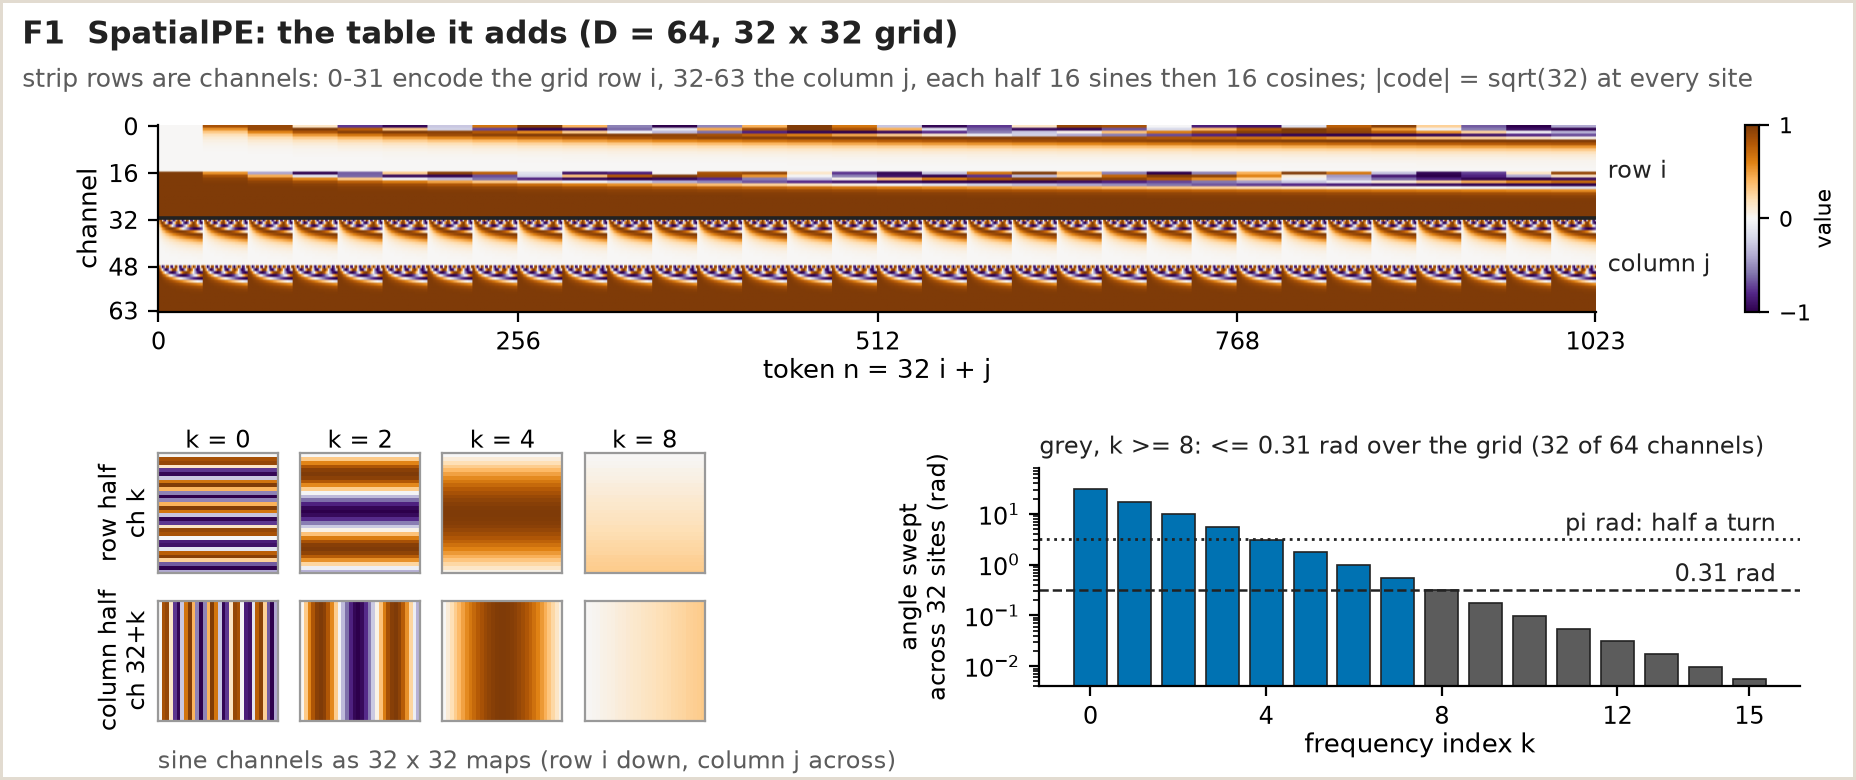

In [3]:
seed_everything()
pe64 = SpatialPE(64)
table = pe64.table(32, 32, dtype=torch.float64)  # (1024, 64), row-major: token n is site (n // 32, n % 32)
norms = table.norm(dim=1)
assert torch.allclose(norms, torch.full_like(norms, math.sqrt(32)), atol=1e-12)
omega = 10000.0 ** (-np.arange(16) / 16)
sweep = 31 * omega  # angle swept between the first and last site of one axis, radians
flat = sweep <= 0.31 + 1e-9
assert flat.sum() == 8 and flat[8:].all()
print(f"code norm at every site: {norms[0].item():.4f} = sqrt(32)")
print("angle swept over 32 sites, k = 0..15 (rad):", np.round(sweep, 3).tolist())
print(f"k >= 8 sweep <= {sweep[8]:.2f} rad: sin stays in [0, {math.sin(sweep[8]):.3f}], cos in [{math.cos(sweep[8]):.3f}, 1]")
print(f"nearly flat: {2 * 2 * int(flat.sum())} of 64 channels")

fig = plt.figure(figsize=SLOT_BAND)
fig_title(fig, "F1  SpatialPE: the table it adds (D = 64, 32 x 32 grid)",
          "strip rows are channels: 0-31 encode the grid row i, 32-63 the column j, each half 16 sines then 16 cosines; |code| = sqrt(32) at every site")
ax = fig.add_axes([0.085, 0.60, 0.775, 0.24])
im = ax.imshow(table.T.numpy(), aspect="auto", cmap=DIV, vmin=-1, vmax=1, interpolation="antialiased")
ax.axhline(31.5, color=INK, lw=1.3)
for c, text in ((15.5, "row i"), (47.5, "column j")):
    ax.text(1.008, 1 - (c + 0.5) / 64, text, transform=ax.transAxes, ha="left", va="center", fontsize=8.5, color=INK)
ax.set_yticks([0, 16, 32, 48, 63])
ax.set_xticks([0, 256, 512, 768, 1023])
ax.set_xlabel("token n = 32 i + j", labelpad=1)
ax.set_ylabel("channel", labelpad=2)
cax = fig.add_axes([0.94, 0.60, 0.008, 0.24])
cb = fig.colorbar(im, cax=cax, ticks=[-1, 0, 1])
cb.ax.tick_params(labelsize=8)
cb.set_label("value", fontsize=8, labelpad=1)

ks = (0, 2, 4, 8)
s_in = 0.60  # each channel map is 0.6 in square
wf, hf = s_in / SLOT_BAND[0], s_in / SLOT_BAND[1]
x0 = 0.085
for r, (half, offset) in enumerate((("row half", 0), ("column half", 32))):
    for c, k in enumerate(ks):
        a = fig.add_axes([x0 + c * (wf + 0.012), 0.265 - r * (hf + 0.035), wf, hf])
        a.imshow(table[:, offset + k].reshape(32, 32).numpy(), cmap=DIV, vmin=-1, vmax=1)
        a.set_xticks([])
        a.set_yticks([])
        for s in a.spines.values():
            s.set_visible(True)
            s.set_color("#999999")
        if r == 0:
            a.set_title(f"k = {k}", fontsize=8.5, pad=2)
        if c == 0:
            a.set_ylabel(f"{half}\nch {offset}+k" if offset else f"{half}\nch k", fontsize=8.5, labelpad=2)
fig.text(x0, 0.015, "sine channels as 32 x 32 maps (row i down, column j across)", fontsize=8.5, color=MUTED, ha="left")

ax = fig.add_axes([0.56, 0.12, 0.41, 0.28])
ax.bar(np.arange(16), sweep, color=[MUTED if f else C_A for f in flat], edgecolor=INK, linewidth=0.6, width=0.75)
ax.set_yscale("log")
ax.axhline(math.pi, color=INK, ls=":", lw=1)
ax.text(15.6, math.pi * 1.15, "pi rad: half a turn", ha="right", va="bottom", fontsize=8.5, color=INK)
ax.axhline(0.31, color=INK, ls="--", lw=0.9)
ax.text(15.6, 0.31 * 1.18, "0.31 rad", ha="right", va="bottom", fontsize=8.5, color=INK)
ax.set_xticks([0, 4, 8, 12, 15])
ax.set_xlabel("frequency index k", labelpad=1)
ax.set_ylabel("angle swept\nacross 32 sites (rad)", fontsize=8.5)
ax.set_ylim(0.004, 80)
ax.text(0.0, 1.04, f"grey, k >= 8: <= 0.31 rad over the grid ({2 * 2 * int(flat.sum())} of 64 channels)",
        transform=ax.transAxes, fontsize=8.5, color=INK, ha="left", va="bottom")
save(fig, "f1a_spatial_pe_table")

## F1, second figure. "Who looks like me"

**What it shows.** For three anchor sites, the distance from the anchor's code to every other site's code, as a 32 by 32 map. Top row `D = 64` (the model), bottom row `D = 8`. Distances are divided by the code norm `sqrt(D / 2)` so both widths share one colour scale (raw distances grow with `sqrt(D)`, which would make `D = 8` look uniformly close). The box marks the anchor's 8 grid neighbours. Dots mark *impostors*: sites outside that box whose code is closer to the anchor than one of its own neighbours. Right: grid distance against code distance for every (anchor, site) pair.

**Takeaway.** At `D = 64` the nearest codes of every one of the 1024 sites are its grid neighbours (the cell counts this for all sites, not just the anchors), and code distance grows with grid distance, roughly but not strictly. At `D = 8` (frequencies 1 and 0.01 only) the fast sine wraps around (`6` and `19` are close to multiples of `2 pi`): at every one of the 1024 sites some farther site has a closer code than one of its neighbours, and each anchor's single closest code is 6 or 19 rows or columns away. That is why the model uses `D = 64`.

**Mirrors** the claim in the `SpatialPE` docstring (8 neighbours at `D = 64`, aliasing at `D = 8`); the tests check distinct codes, not the neighbour order, so this cell is the check.

**Could mislead.** This is the position code alone. The model adds it to content tokens, and the spatial blocks see `LayerNorm(token + code)`, so "close codes" does not mean "attend to each other".

D = 64: 1024 of 1024 sites have their grid neighbours as their nearest codes
   anchor (16, 16): nearest code at site (15, 16) (offset -1, +0), distance 0.207; farthest neighbour 0.293; 0 impostors
   anchor (4, 4): nearest code at site (4, 5) (offset +0, +1), distance 0.207; farthest neighbour 0.293; 0 impostors
   anchor (9, 26): nearest code at site (10, 26) (offset +1, +0), distance 0.207; farthest neighbour 0.293; 0 impostors
D = 8: 0 of 1024 sites have their grid neighbours as their nearest codes
   anchor (16, 16): nearest code at site (16, 22) (offset +0, +6), distance 0.144; farthest neighbour 0.678; 152 impostors
   anchor (4, 4): nearest code at site (4, 23) (offset +0, +19), distance 0.121; farthest neighbour 0.678; 160 impostors
   anchor (9, 26): nearest code at site (28, 26) (offset +19, +0), distance 0.121; farthest neighbour 0.678; 167 impostors
saved docs/figures/model/f1b_who_looks_like_me.png


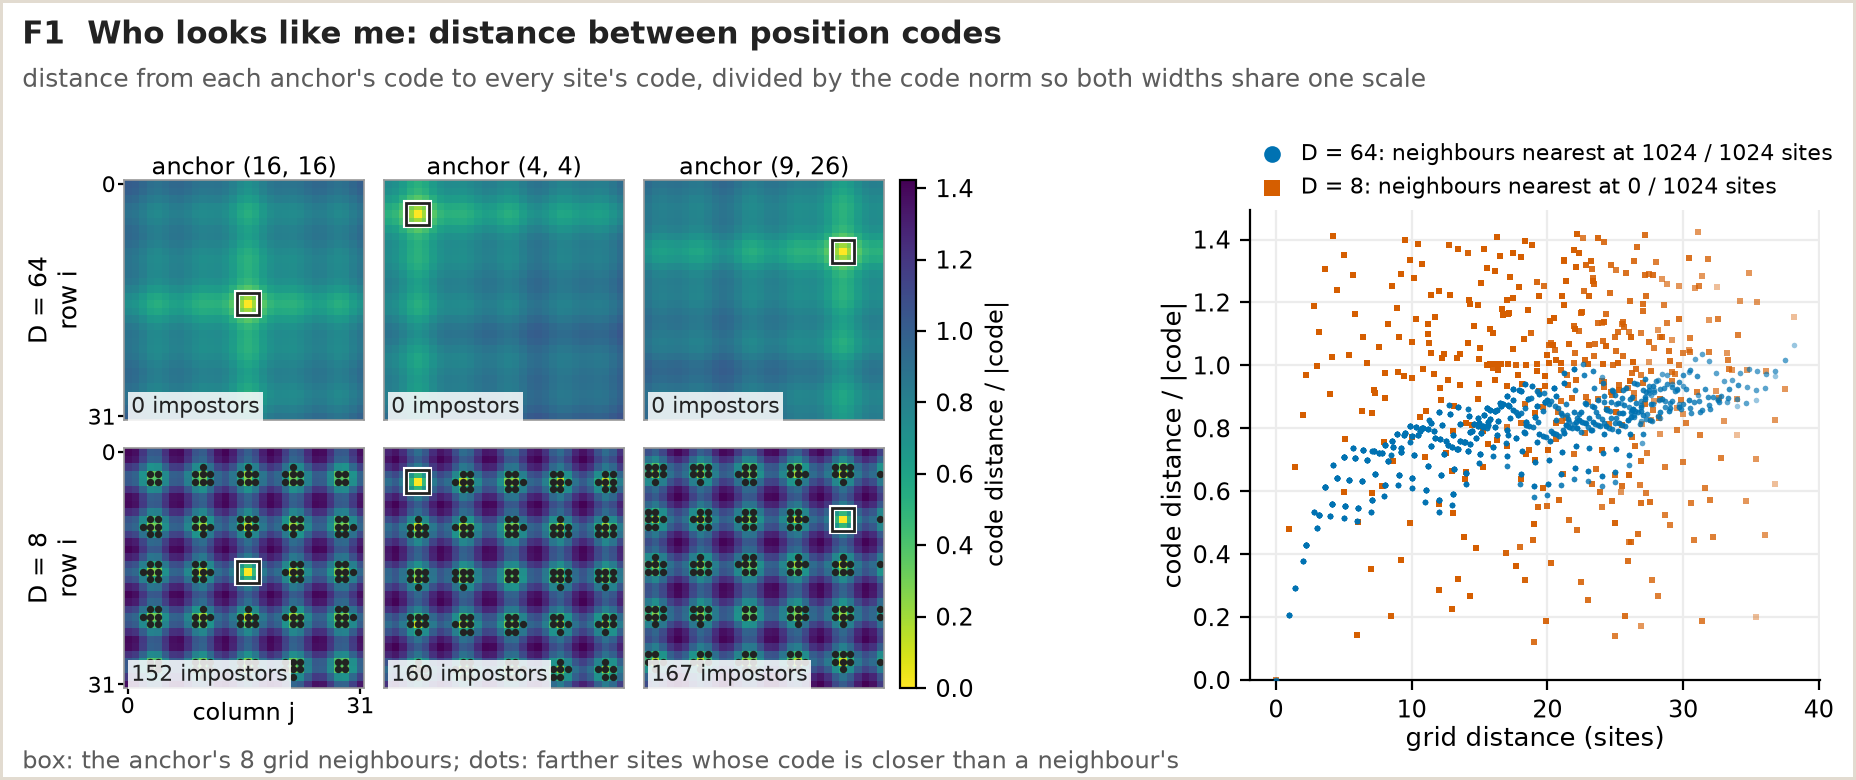

In [4]:
seed_everything()
ANCHORS = [(16, 16), (4, 4), (9, 26)]
ii, jj = np.divmod(np.arange(1024), 32)
cheb = np.maximum(np.abs(ii[:, None] - ii[None]), np.abs(jj[:, None] - jj[None]))
grid_dist = np.hypot(ii[:, None] - ii[None], jj[:, None] - jj[None])
pe_stats = {}
for D in (64, 8):
    code = SpatialPE(D).table(32, 32, dtype=torch.float64)
    dist = (torch.cdist(code, code) / math.sqrt(D / 2)).numpy()
    nb_max = np.where(cheb == 1, dist, -np.inf).max(1)
    non_min = np.where(cheb > 1, dist, np.inf).min(1)
    ok = int((nb_max < non_min).sum())
    pe_stats[D] = dict(dist=dist, ok=ok, nb_max=nb_max)
    print(f"D = {D}: {ok} of 1024 sites have their grid neighbours as their nearest codes")
    for a in ANCHORS:
        n = a[0] * 32 + a[1]
        d = dist[n].copy()
        d[n] = np.inf
        near = int(d.argmin())
        imp = int(((cheb[n] > 1) & (dist[n] < nb_max[n])).sum())
        print(f"   anchor {a}: nearest code at site {divmod(near, 32)} "
              f"(offset {near // 32 - a[0]:+d}, {near % 32 - a[1]:+d}), distance {d[near]:.3f}; "
              f"farthest neighbour {nb_max[n]:.3f}; {imp} impostors")
assert pe_stats[64]["ok"] == 1024
vmax = max(pe_stats[D]["dist"][[a[0] * 32 + a[1] for a in ANCHORS]].max() for D in (64, 8))

fig = plt.figure(figsize=SLOT_BAND)
fig_title(fig, "F1  Who looks like me: distance between position codes",
          "distance from each anchor's code to every site's code, divided by the code norm so both widths share one scale")
MAP = 1.20  # inches, square
for r, D in enumerate((64, 8)):
    dist = pe_stats[D]["dist"]
    for c, a in enumerate(ANCHORS):
        n = a[0] * 32 + a[1]
        ax = ax_in(fig, 0.62 + c * (MAP + 0.10), 1.80 - r * (MAP + 0.14), MAP, MAP)
        im = ax.imshow(dist[n].reshape(32, 32), cmap=SEQ + "_r", vmin=0, vmax=vmax)
        frame(ax)
        ax.add_patch(Rectangle((a[1] - 1.5, a[0] - 1.5), 3, 3, fill=False, ec="white", lw=2.2))
        ax.add_patch(Rectangle((a[1] - 1.5, a[0] - 1.5), 3, 3, fill=False, ec=INK, lw=1.0))
        imp = np.nonzero((cheb[n] > 1) & (dist[n] < pe_stats[D]["nb_max"][n]))[0]
        if len(imp):
            ax.scatter(imp % 32, imp // 32, s=7, c=INK, linewidths=0)
        ax.set_xticks([0, 31] if (r == 1 and c == 0) else [])
        ax.set_yticks([0, 31] if c == 0 else [])
        ax.tick_params(labelsize=8, length=2, pad=1)
        if r == 0:
            ax.set_title(f"anchor {a}", fontsize=8.5, pad=2)
        if c == 0:
            ax.set_ylabel(f"D = {D}\nrow i", fontsize=9, labelpad=1)
        if r == 1 and c == 0:
            ax.set_xlabel("column j", labelpad=-6, fontsize=8.5)
        ax.text(0.03, 0.03, f"{len(imp)} impostors", transform=ax.transAxes, fontsize=8, color=INK,
                bbox=dict(facecolor="white", edgecolor="none", pad=1.2, alpha=0.85))
cax = ax_in(fig, 0.62 + 3 * (MAP + 0.10) - 0.02, 0.46, 0.08, 2 * MAP + 0.14)
fig.colorbar(im, cax=cax).set_label("code distance / |code|", fontsize=8.5)

ax = ax_in(fig, 6.25, 0.50, 2.85, 2.35)
for D, color, marker, z in ((8, C_B, "s", 2), (64, C_A, "o", 3)):
    xs = np.concatenate([grid_dist[a[0] * 32 + a[1]] for a in ANCHORS])
    ys = np.concatenate([pe_stats[D]["dist"][a[0] * 32 + a[1]] for a in ANCHORS])
    ax.scatter(xs, ys, s=4, color=color, alpha=0.4, linewidths=0, marker=marker, zorder=z,
               label=f"D = {D}: neighbours nearest at {pe_stats[D]['ok']} / 1024 sites")
ax.set_xlabel("grid distance (sites)", labelpad=1)
ax.set_ylabel("code distance / |code|", labelpad=2)
ax.set_ylim(0, vmax * 1.05)
ax.grid(color=GRID)
ax.set_axisbelow(True)
handles, labels = ax.get_legend_handles_labels()
leg = ax.legend(handles[::-1], labels[::-1], loc="lower left", bbox_to_anchor=(-0.02, 1.0), frameon=False,
                markerscale=3, handletextpad=0.3, borderaxespad=0.1, fontsize=8)
for h in leg.legend_handles:
    h.set_alpha(1)
fig.text(0.012, 0.015, "box: the anchor's 8 grid neighbours; dots: farther sites whose code is closer than a neighbour's",
         fontsize=8.5, color=MUTED)
save(fig, "f1b_who_looks_like_me")

## F2 (PR 2, SpatialBlock). Where a patch looks

**What it shows.** The attention weights of three query patches in spatial block 1 (`model.spatial[0]`), read with a forward hook on `model.spatial[0].attn` (the from-scratch `MultiHeadSelfAttention` returns `(out, weights)` and the block discards the weights). Each query's row of weights, `(N,)`, is reshaped to the patch grid, one map per head. Colour is the weight times `N`: 1 means "as much as a uniform average", above 1 orange, below 1 purple, on one log scale for every panel. The input is the val cube with filament and the most classes when `SW_ROOT` is set, otherwise a synthetic scene (labelled). The trained column appears only when `CKPT` is set.

**Takeaway.** At init every query attends almost uniformly: weights are about `1 / N = 1 / 1024`, and the entropy is close to its maximum `ln N`. Whatever structure a trained model shows was learned.

**Mirrors** `test_spatial_block_attends_across_tokens` (a token's change moves the others) and `test_band_transformer_runs_the_spatial_blocks_in_order` (the hook point).

**Could mislead.** Attention is not attribution: a large weight says where a value vector was read from, not what changed the prediction (the value can be near zero, the residual path and the MLP carry the rest, and later blocks re-mix everything). And spatial block 1 sees tokens after two spectral blocks and the position code, so even at init the weights are not exactly uniform.

SKIP F2 trained column: CKPT not set; drawing the init column only
input: synthetic scene (SW_ROOT not set), 256 x 256 px, grid 32 x 32, N = 1024, uniform weight 1/N = 9.77e-04
  init    Q1 (bag        patch (5, 6)): w*N in [0.692, 1.607], entropy / ln N per head 0.9985 0.9994 0.9990 0.9991
  init    Q2 (filament   patch (13, 3)): w*N in [0.679, 1.360], entropy / ln N per head 0.9992 0.9991 0.9990 0.9991
  init    Q3 (background patch (15, 16)): w*N in [0.693, 1.517], entropy / ln N per head 0.9990 0.9991 0.9990 0.9994
saved docs/figures/model/f2_where_a_patch_looks.png


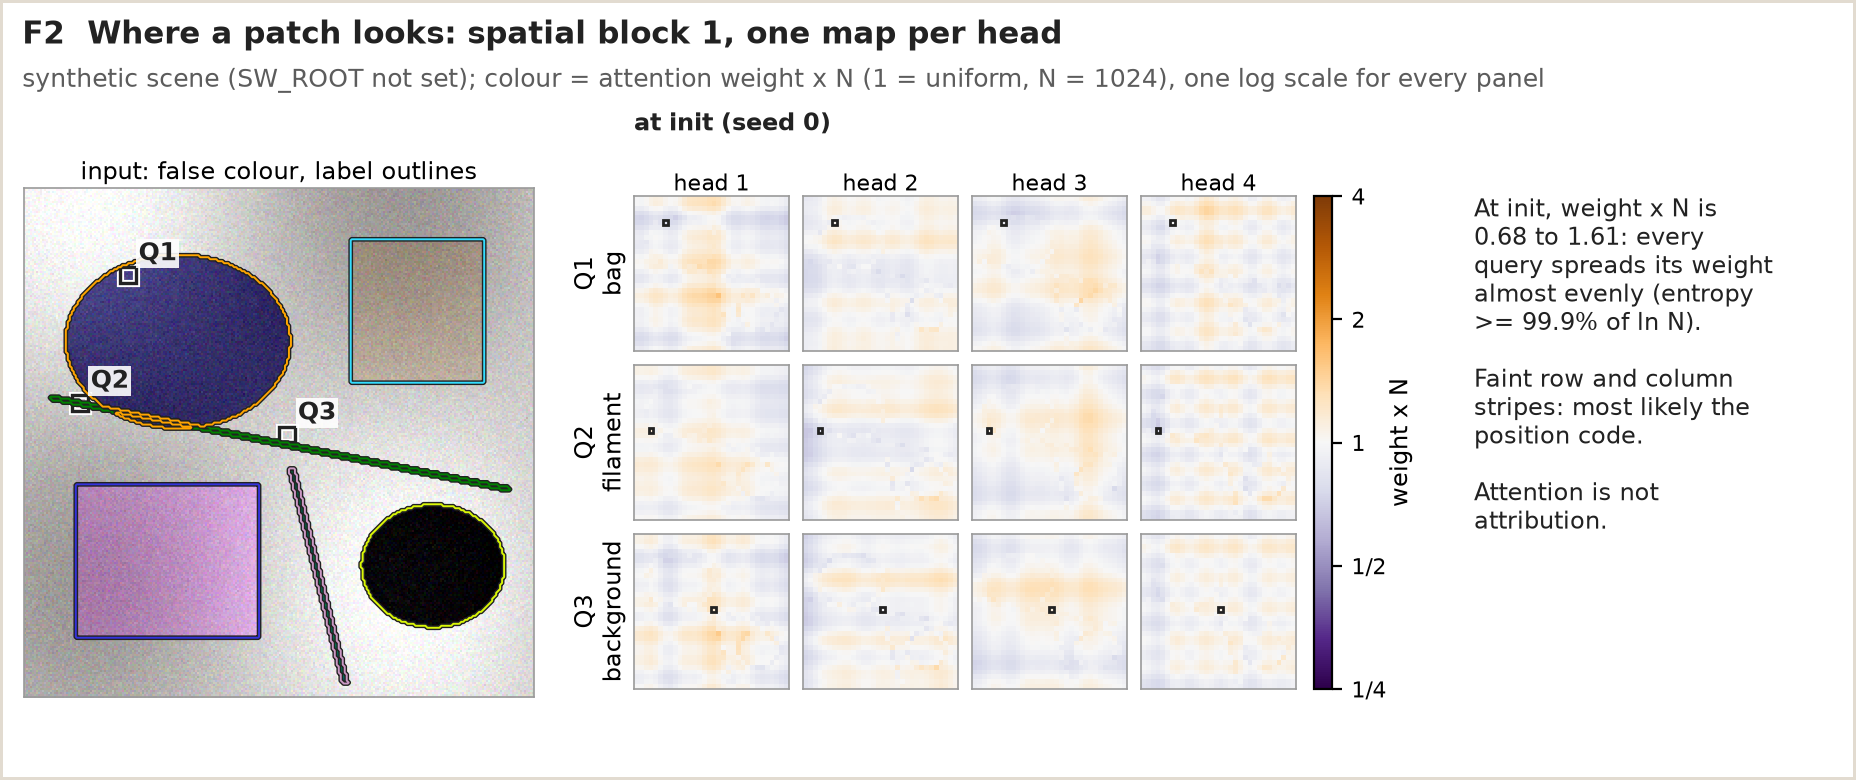

In [5]:
seed_everything()
SPATIAL_BLOCK = 0  # spatial block 1 of 6
example = val_example()
if example is None:
    cube_np, mask_np = synthetic_scene(SEED)
    source = "synthetic scene (SW_ROOT not set)"
else:
    cube_np, mask_np, stem = example
    source = f"val cube {stem}"
loaded = load_ckpt()
cfg = loaded[1] if loaded else {}
ds_factor = int(cfg.get("downsample", 1) or 1)
x_t, m_t = prepare_sample(torch.from_numpy(cube_np), torch.from_numpy(mask_np), train=False, crop_size=None, downsample=ds_factor)
x_np, m_np = x_t.numpy(), m_t.numpy()
patch = int(cfg.get("patch", PATCH))
gh, gw = x_np.shape[1] // patch, x_np.shape[2] // patch
major, purity, counts = patch_labels(m_np, patch, gh, gw)

# Three queries: the purest patch of the commonest object class, the patch with the most
# thin-class pixels (filament, else tape), and a pure background patch near the centre.
queries = []
obj = [c for c in range(1, 7) if (major == c).any()]
if obj:
    c1 = max(obj, key=lambda c: (major == c).sum())
    cand = np.nonzero(major == c1)[0]
    queries.append((int(cand[np.argmax(purity[cand])]), c1))
for thin in (5, 4):
    if counts[:, thin].max() > 0:
        queries.append((int(counts[:, thin].argmax()), thin))
        break
bg = np.nonzero((major == 0) & (purity == 1))[0]
if len(bg):
    centre = np.hypot(bg // gw - gh / 2, bg % gw - gw / 2)
    queries.append((int(bg[centre.argmin()]), 0))
queries = queries[:3]


def spatial_attention(model, x, block):
    store = {}
    handle = model.spatial[block].attn.register_forward_hook(lambda mod, args, out: store.update(w=out[1].detach()))
    try:
        with torch.no_grad():
            model(x[None])
    finally:
        handle.remove()
    return store["w"][0]  # (H, N, N)


seed_everything()
init_model = build_transformer(cfg).eval()
if init_model.depth_spatial == 0:
    skip("F2", "this config has no spatial blocks")
else:
    columns = [("init", spatial_attention(init_model, x_t, SPATIAL_BLOCK))]
    trained = trained_model()
    if trained is None:
        skip("F2 trained column", "CKPT not set; drawing the init column only")
    else:
        columns.append(("trained", spatial_attention(trained, x_t, SPATIAL_BLOCK)))
    N = gh * gw
    heads = columns[0][1].shape[0]
    print(f"input: {source}, {x_np.shape[1]} x {x_np.shape[2]} px, grid {gh} x {gw}, N = {N}, uniform weight 1/N = {1 / N:.2e}")
    for name, w in columns:
        for qi, (n, c) in enumerate(queries):
            row = w[:, n, :]  # (H, N)
            ent = -(row * row.clamp_min(1e-30).log()).sum(-1) / math.log(N)
            print(f"  {name:7s} Q{qi + 1} ({LABEL[CLASS_NAMES[c]]:10s} patch {divmod(n, gw)}): "
                  f"w*N in [{(row * N).min():.3f}, {(row * N).max():.3f}], entropy / ln N per head "
                  + " ".join(f"{e:.4f}" for e in ent.tolist()))
    allw = torch.cat([w[:, [n for n, _ in queries], :].flatten() for _, w in columns]) * N
    R = float(max(4.0, allw.max(), 1 / allw.min().clamp_min(1e-12)))
    R = min(R, float(N))
    norm = LogNorm(vmin=1 / R, vmax=R)

    FW, FH = SLOT_BAND
    n_sets = len(columns)
    n_cols = n_sets * heads
    img_in = 2.55 if n_sets == 1 else 1.95
    grid_bottom, grid_top, gap, set_gap = 0.40, FH - 0.98, 0.07, 0.22
    maps_left = 0.12 + img_in + 0.50
    right_reserve = 0.80 + (2.0 if n_sets == 1 else 0)  # colour bar, plus a notes column with one set
    cell = min((grid_top - grid_bottom - 2 * gap) / 3,
               (FW - maps_left - right_reserve - (n_cols - 1) * gap - (n_sets - 1) * set_gap) / n_cols)
    grid_h = 3 * cell + 2 * gap
    grid_bottom = grid_top - grid_h  # hang the grid from the top, so any spare height goes below

    fig = plt.figure(figsize=SLOT_BAND)
    fig_title(fig, f"F2  Where a patch looks: spatial block {SPATIAL_BLOCK + 1}, one map per head",
              f"{source}; colour = attention weight x N (1 = uniform, N = {N}), one log scale for every panel")
    ax = ax_in(fig, 0.12, grid_bottom + (grid_h - img_in) / 2, img_in, img_in)
    ax.imshow(false_colour(x_np))
    frame(ax)
    outline(ax, m_np, lw=0.7)
    for qi, (n, c) in enumerate(queries):
        i, j = divmod(n, gw)
        ax.add_patch(Rectangle((j * patch - 0.5, i * patch - 0.5), patch, patch, fill=False, ec="white", lw=2.6))
        ax.add_patch(Rectangle((j * patch - 0.5, i * patch - 0.5), patch, patch, fill=False, ec=INK, lw=1.2))
        ax.text(j * patch + patch + 1, i * patch - 1, f"Q{qi + 1}", color=INK, fontsize=9, fontweight="bold",
                ha="left", va="bottom", bbox=dict(facecolor="white", edgecolor="none", pad=0.8, alpha=0.9))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title("input: false colour, label outlines", fontsize=8.5, pad=3)
    for k, (name, w) in enumerate(columns):
        for qi, (n, c) in enumerate(queries):
            for hd in range(heads):
                left = maps_left + (k * heads + hd) * (cell + gap) + k * set_gap
                a = ax_in(fig, left, grid_bottom + (2 - qi) * (cell + gap), cell, cell)
                im = a.imshow((w[hd, n] * N).reshape(gh, gw).numpy(), cmap=DIV, norm=norm)
                frame(a)
                i, j = divmod(n, gw)
                a.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=INK, lw=1.0))
                a.set_xticks([])
                a.set_yticks([])
                if qi == 0:
                    a.set_title(f"head {hd + 1}", fontsize=8, pad=2)
                    if hd == 0:
                        set_label = "at init (seed 0)" if name == "init" else f"trained ({CKPT.name})"
                        a.text(0.0, 1.0 + 0.30 / cell, set_label, transform=a.transAxes, fontsize=8.5,
                               fontweight="bold", color=INK, ha="left", va="bottom")
                if hd == 0 and k == 0:
                    a.set_ylabel(f"Q{qi + 1}\n{LABEL[CLASS_NAMES[c]]}", fontsize=8.5, labelpad=2)
    cbar_left = maps_left + n_cols * (cell + gap) + (n_sets - 1) * set_gap + 0.02
    cax = ax_in(fig, cbar_left, grid_bottom, 0.09, grid_h)
    ticks = [t for t in (1 / 1024, 1 / 64, 1 / 16, 1 / 4, 1 / 2, 1, 2, 4, 16, 64, 1024) if 1 / R <= t <= R]
    cb = fig.colorbar(im, cax=cax, ticks=ticks)
    cb.ax.set_yticklabels([f"{t:g}" if t >= 1 else f"1/{1 / t:g}" for t in ticks], fontsize=8)
    cb.ax.minorticks_off()
    cb.set_label("weight x N", fontsize=8.5, labelpad=1)
    init_row = columns[0][1][:, [n for n, _ in queries], :] * N
    init_ent = min((-(r * r.clamp_min(1e-30).log()).sum(-1) / math.log(N)).min().item()
                   for r in [columns[0][1][:, n, :] for n, _ in queries])
    note = (f"At init, weight x N is\n{init_row.min():.2f} to {init_row.max():.2f}: every\nquery spreads its weight\n"
            f"almost evenly (entropy\n>= {init_ent:.1%} of ln N).\n\nFaint row and column\nstripes: most likely the\n"
            "position code.\n\nAttention is not\nattribution.")
    if n_sets == 1:
        fig.text((cbar_left + 0.80) / FW, (grid_bottom + grid_h) / FH, note, fontsize=8.5, color=INK, ha="left", va="top")
    else:
        fig.text(maps_left / FW, (grid_bottom - 0.30) / FH, f"init: weight x N {init_row.min():.2f} to {init_row.max():.2f}. "
                 "Attention is not attribution.", fontsize=8.5, color=INK, ha="left", va="top")
    save(fig, "f2_where_a_patch_looks")

## F3 (PR 3, SegHead). One-token poke

**What it shows.** `SegHead` alone, at init, fed all-zero tokens, then the same tokens with one token set to random values. The map is `|delta logits|` summed over the 7 classes, on a log scale; pixels whose logits did not change at all are light grey. The poked token's own 8-pixel patch is outlined. Left: a 9 by 9 grid (72 by 72 px). Middle: a 30 by 40 image, which is not a multiple of the patch: the tokenizer covers 24 by 40, and rows 24 to 29 (hatched) are replicate-padded copies of row 23. Right: the farthest any token reaches outside its own patch, measured over every token of three sizes.

**Takeaway.** Each token paints its own patch plus a halo a little wider than one patch, never two: the reach is 13 px when the image is a multiple of the patch and up to `2 * patch - 1 = 15` px with a remainder, as the docstring says. Nothing is stretched: the padded rows copy the last covered row instead of shifting every token off its pixels.

**Mirrors** `test_seg_head_keeps_each_token_over_its_own_patch` (the 13 and 15 px reach and the padded rows) and `test_seg_head_shape` (30 by 40).

**Could mislead.** This is the head alone. In the full model every spatial block mixes all tokens, so a change to one input patch reaches the whole image before it gets to the head. The halo's size depends only on the kernel sizes; its shape and strength depend on the (random) weights.

48 x 56 on a 6 x 7 grid: farthest reach outside the own patch 13 px
30 x 40 on a 3 x 5 grid: farthest reach outside the own patch 14 px
55 x 63 on a 6 x 7 grid: farthest reach outside the own patch 15 px
saved docs/figures/model/f3_one_token_poke.png


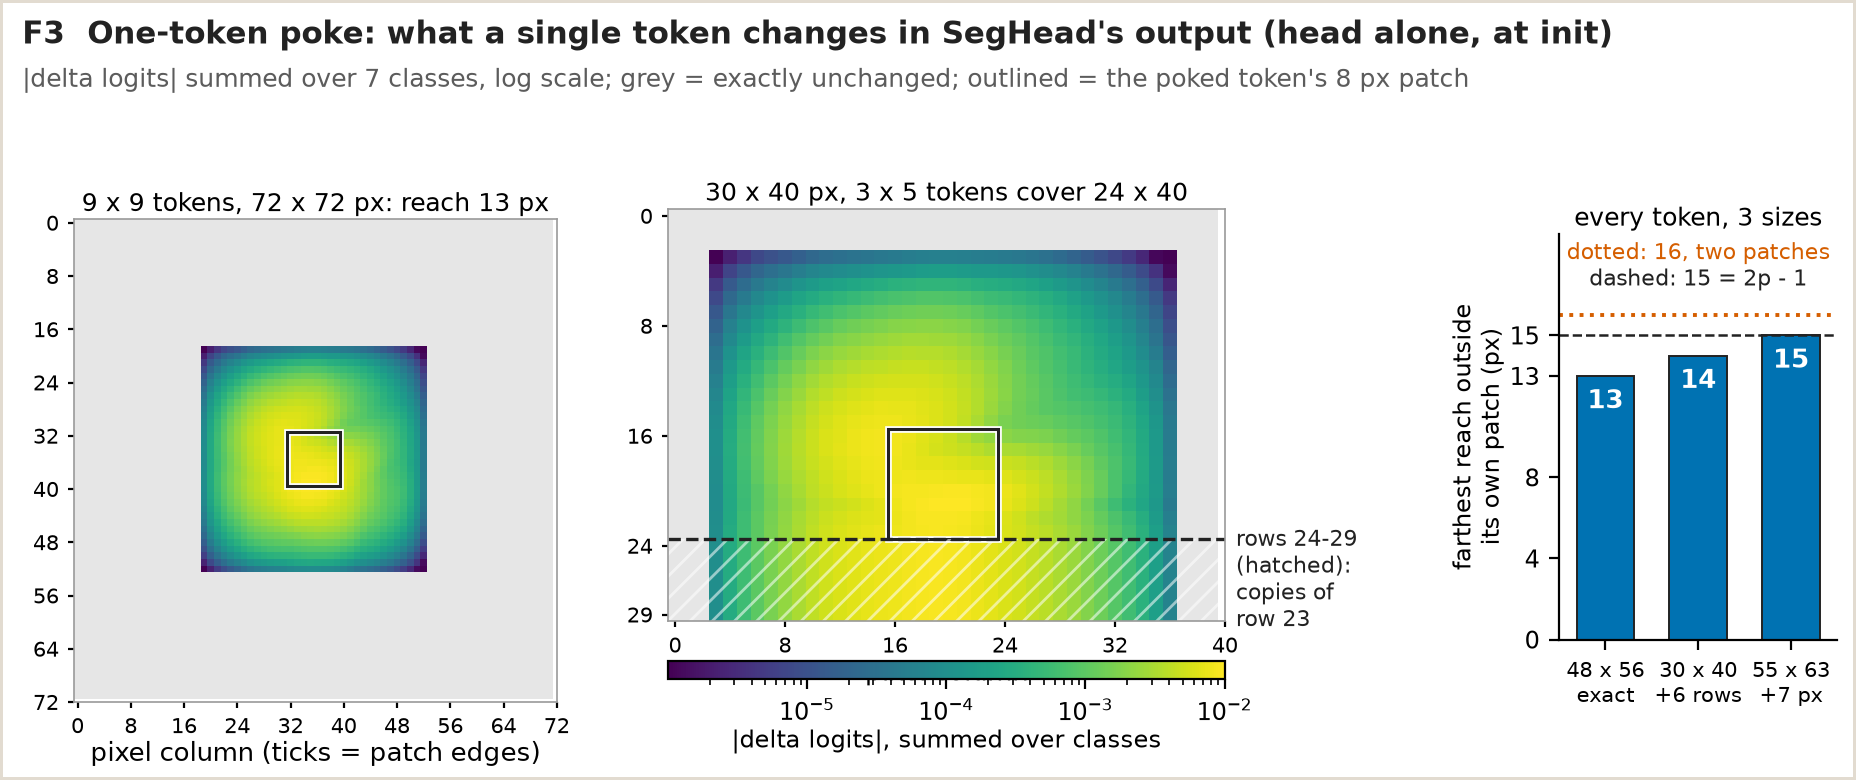

In [6]:
seed_everything()
head = SegHead(dim=64, num_classes=7, patch=PATCH).eval()


def poke(head, h, w, n, out_size, seed=SEED):
    g = torch.Generator().manual_seed(seed)
    with torch.no_grad():
        base = head(torch.zeros(1, h * w, 64), h, w, out_size=out_size)
        tokens = torch.zeros(1, h * w, 64)
        tokens[0, n] = torch.randn(64, generator=g)
        return (head(tokens, h, w, out_size=out_size) - base).abs().sum(dim=1)[0]  # (H, W)


def reach(change, i, j, patch=PATCH):
    """How far, in pixels, the changed region extends outside patch (i, j). Same rule as the test."""
    rows, cols = torch.nonzero(change > 0, as_tuple=True)
    top, left = i * patch, j * patch
    outside = torch.stack([top - rows, rows - (top + patch - 1), left - cols, cols - (left + patch - 1), torch.zeros_like(rows)])
    return int(outside.max())


REACH_CASES = [((6, 7), (48, 56), "48 x 56\nexact"), ((3, 5), (30, 40), "30 x 40\n+6 rows"), ((6, 7), (55, 63), "55 x 63\n+7 px")]
measured_reach = []
for (h, w), size, label in REACH_CASES:
    r = max(reach(poke(head, h, w, n, size, seed=SEED + n), *divmod(n, w)) for n in range(h * w))
    measured_reach.append(r)
    print(f"{size[0]} x {size[1]} on a {h} x {w} grid: farthest reach outside the own patch {r} px")

big = poke(head, 9, 9, 4 * 9 + 4, (72, 72))
odd = poke(head, 3, 5, 2 * 5 + 2, (30, 40))
vmax = float(max(big.max(), odd.max()))
norm = LogNorm(vmin=vmax * 1e-4, vmax=vmax)
cmap = plt.get_cmap(SEQ).copy()
cmap.set_bad("#e6e6e6")
cmap.set_under(cmap(0.0))

fig = plt.figure(figsize=SLOT_BAND)
fig_title(fig, "F3  One-token poke: what a single token changes in SegHead's output (head alone, at init)",
          "|delta logits| summed over 7 classes, log scale; grey = exactly unchanged; outlined = the poked token's 8 px patch")
ax = fig.add_axes([0.04, 0.10, 0.26, 0.26 * SLOT_BAND[0] / SLOT_BAND[1]])
im = ax.imshow(np.ma.masked_equal(big.numpy(), 0), cmap=cmap, norm=norm)
frame(ax)
ax.add_patch(Rectangle((4 * 8 - 0.5, 4 * 8 - 0.5), 8, 8, fill=False, ec="white", lw=2.4))
ax.add_patch(Rectangle((4 * 8 - 0.5, 4 * 8 - 0.5), 8, 8, fill=False, ec=INK, lw=1.1))
r_big = reach(big, 4, 4)
ax.set_title(f"9 x 9 tokens, 72 x 72 px: reach {r_big} px", fontsize=9, pad=3)
ax.set_xticks(range(0, 73, 8))
ax.set_yticks(range(0, 73, 8))
ax.tick_params(labelsize=7.5, length=2)
ax.set_xlabel("pixel column (ticks = patch edges)", labelpad=1)

ax = fig.add_axes([0.36, 0.20, 0.30, 0.30 * 30 / 40 * SLOT_BAND[0] / SLOT_BAND[1]])
ax.imshow(np.ma.masked_equal(odd.numpy(), 0), cmap=cmap, norm=norm)
frame(ax)
ax.add_patch(Rectangle((2 * 8 - 0.5, 2 * 8 - 0.5), 8, 8, fill=False, ec="white", lw=2.4))
ax.add_patch(Rectangle((2 * 8 - 0.5, 2 * 8 - 0.5), 8, 8, fill=False, ec=INK, lw=1.1))
ax.add_patch(Rectangle((-0.5, 23.5), 40, 6, fill=False, ec="white", lw=0, hatch="///", alpha=0.55))
ax.axhline(23.5, color=INK, lw=1.2, ls="--")
ax.set_title("30 x 40 px, 3 x 5 tokens cover 24 x 40", fontsize=9, pad=3)
ax.set_xticks(range(0, 41, 8))
ax.set_yticks([0, 8, 16, 24, 29])
ax.tick_params(labelsize=7.5, length=2)
ax.text(40.8, 26.5, "rows 24-29\n(hatched):\ncopies of\nrow 23", fontsize=8, color=INK, va="center", ha="left")
ax.set_xlabel("pixel column", labelpad=1)
cax = fig.add_axes([0.36, 0.13, 0.30, 0.022])
fig.colorbar(im, cax=cax, orientation="horizontal").set_label("|delta logits|, summed over classes", fontsize=8.5, labelpad=1)

ax = fig.add_axes([0.84, 0.18, 0.15, 0.52])
xs = np.arange(len(REACH_CASES))
ax.bar(xs, measured_reach, color=C_A, edgecolor=INK, linewidth=0.7, width=0.62)
for x_, r in zip(xs, measured_reach):
    ax.text(x_, r - 0.6, f"{r}", ha="center", va="top", fontsize=9.5, color="white", fontweight="bold")
ax.axhline(2 * PATCH - 1, color=INK, ls="--", lw=0.9)
ax.axhline(2 * PATCH, color=C_B, ls=":", lw=1.4)
ax.text(1.0, 19.6, "dotted: 16, two patches", fontsize=8, color=C_B, ha="center", va="top")
ax.text(1.0, 18.3, "dashed: 15 = 2p - 1", fontsize=8, color=INK, ha="center", va="top")
ax.set_xticks(xs, [c[2] for c in REACH_CASES], fontsize=7.5)
ax.set_yticks([0, 4, 8, 13, 15])
ax.set_ylim(0, 20)
ax.set_xlim(-0.5, 2.5)
ax.set_ylabel("farthest reach outside\nits own patch (px)", fontsize=8.5, labelpad=1)
ax.set_title("every token, 3 sizes", fontsize=9, pad=3)
save(fig, "f3_one_token_poke")

## F4 (PR 4, skip; planned). Why a 1-pixel filament needs a full-resolution path

**What it shows.** A closed form, not a model run. Take a straight, axis-aligned line of width 1 to 16 px and a predictor whose output is constant on each cell of the image (8 px for patch-constant, 2 px for comparison, 1 px for full resolution). Even if the predictor knows exactly where the line is, the best it can do is mark some whole cells, so its IoU is bounded. The curve is the best IoU, averaged over the line's offset inside a cell, with the band from the worst to the best offset. For a line that fits inside one cell, aligned, the bound is `width / cell`.

**Takeaway.** A 1 px line gets at most 12.5% IoU from a patch-constant predictor at patch 8 (and 2 px at most 25%). Filament and video tape are 1 to 2 px wide (the `SegHead` docstring); that is the motivation for the full-resolution spectral skip in PR 4.

**Mirrors** the "A limit to know" paragraph of the `SegHead` docstring; no test.

**Could mislead.** It is a bound for predictors that are constant per cell. The real head is not: its 3 by 3 convs at stride 4 and 2 and the final bilinear step vary inside a patch, so it can beat the patch-8 curve in principle (its learned detail stops at stride 2). The curve says what resolution a thin line needs, not what SegHead will score. The with/without-skip crop of a real filament is **after PR 4**: there is no skip in this commit, so that panel is skipped below.

patch-constant (8 px) best IoU, mean over offsets, widths 1..16: [12.5, 23.4, 33.7, 42.7, 50.2, 56.7, 62.0, 65.7, 67.8, 69.3, 70.7, 71.9, 73.7, 75.9, 77.9, 79.4]
1 px line: at most 12.5% (aligned), 12.5% on average over offsets
2 px line: at most 25.0%; 2-px cells give 50.0% for a 1 px line


saved docs/figures/model/f4_patch_bound.png


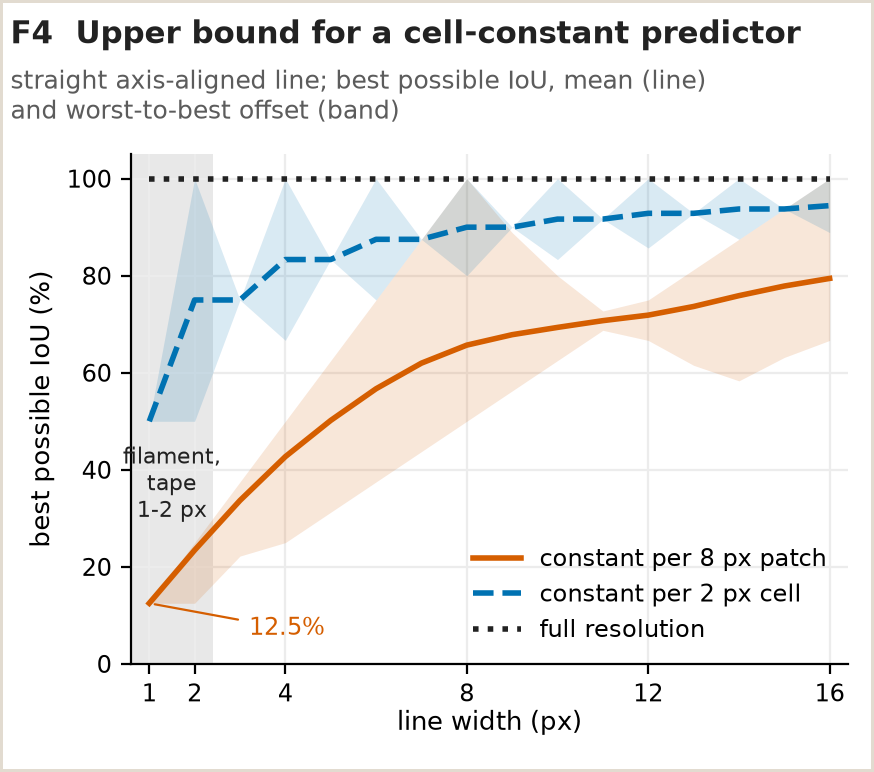

SKIP F4 skip crop: with/without full-resolution skip needs PR 4 (no skip in this commit)


In [7]:
from itertools import combinations


def best_iou(width, offset, cell):
    """Best IoU of a cell-constant prediction for pixels [offset, offset + width) on a 1-D axis."""
    first, last = offset // cell, (offset + width - 1) // cell
    overlaps = [min((c + 1) * cell, offset + width) - max(c * cell, offset) for c in range(first, last + 1)]
    best = 0.0
    for size in range(1, len(overlaps) + 1):
        for chosen in combinations(overlaps, size):
            inter = sum(chosen)
            best = max(best, inter / (size * cell + width - inter))
    return best


widths = np.arange(1, 17)
bound = {}
for cell in (8, 2, 1):
    table_ = np.array([[best_iou(int(w_), o, cell) for o in range(cell)] for w_ in widths])
    bound[cell] = (table_.mean(1), table_.min(1), table_.max(1))
assert abs(bound[8][2][0] - 1 / 8) < 1e-12 and abs(bound[8][2][1] - 2 / 8) < 1e-12
print("patch-constant (8 px) best IoU, mean over offsets, widths 1..16:", np.round(bound[8][0] * 100, 1).tolist())
print(f"1 px line: at most {bound[8][2][0]:.1%} (aligned), {bound[8][0][0]:.1%} on average over offsets")
print(f"2 px line: at most {bound[8][2][1]:.1%}; 2-px cells give {bound[2][0][0]:.1%} for a 1 px line")

fig, ax = plt.subplots(figsize=SLOT_CHART)
fig.subplots_adjust(left=0.15, right=0.97, top=0.80, bottom=0.14)
fig_title(fig, "F4  Upper bound for a cell-constant predictor",
          "straight axis-aligned line; best possible IoU, mean (line)\nand worst-to-best offset (band)")
for cell, color, ls, label in ((8, C_B, "-", "constant per 8 px patch"), (2, C_A, "--", "constant per 2 px cell"), (1, INK, ":", "full resolution")):
    mean, lo, hi = bound[cell]
    ax.fill_between(widths, lo * 100, hi * 100, color=color, alpha=0.15, linewidth=0)
    ax.plot(widths, mean * 100, ls, color=color, lw=2, label=label)
ax.axvspan(0.6, 2.4, color="#d9d9d9", alpha=0.6, zorder=0, lw=0)
ax.text(1.5, 37, "filament,\ntape\n1-2 px", ha="center", va="center", fontsize=8, color=INK)
ax.annotate(f"{bound[8][2][0]:.1%}", xy=(1, bound[8][2][0] * 100), xytext=(3.2, 6), fontsize=8.5, color=C_B,
            arrowprops=dict(arrowstyle="-", color=C_B, lw=0.8))
ax.set_xlim(0.6, 16.4)
ax.set_ylim(0, 105)
ax.set_xticks([1, 2, 4, 8, 12, 16])
ax.set_xlabel("line width (px)", labelpad=1)
ax.set_ylabel("best possible IoU (%)")
ax.grid(color=GRID)
ax.set_axisbelow(True)
ax.legend(loc="lower right", frameon=False)
save(fig, "f4_patch_bound")
skip("F4 skip crop", "with/without full-resolution skip needs PR 4 (no skip in this commit)")

## F5 (PR 5, stochastic depth; planned schedule). DropPath masks

**What it shows.** Left: 16 images (rows) through the 8 blocks of the default model (2 spectral, then 6 spatial), with the planned linear schedule `p_i = 0.1 * i / 7` for block `i = 0..7`. Each block has two residual branches (attention, then MLP), each drawn with its own `DropPath(p_i)` call; black means that branch was dropped for that image. Right: over many draws, a batch of 16 images through `DropPath(0.1)` (the deepest block), the batch mean of training output divided by eval output.

**Takeaway.** A drop removes a whole branch for a whole image, rarely and more often deeper in the stack, and the kept branches are scaled by `1 / (1 - p)` so the mean matches eval (the histogram is centred on 1).

**Mirrors** `test_drop_path_drops_whole_samples_and_keeps_the_mean` and `test_spatial_block_drop_path_is_per_image_and_off_in_eval`.

**Could mislead.** This is the **planned** schedule, drawn with `DropPath` directly. In this commit `BandTransformer` builds every `SpatialBlock` with `drop_path = 0`, and `SpectralBlock` has no drop path at all; it folds tokens into the batch axis, `(B * N, G, D)`, so a drop there must reshape back to `(B, ...)` first or it drops per token, not per image (the `DropPath` docstring). Wiring the schedule is PR 5.

planned p per block: [0.0, 0.0143, 0.0286, 0.0429, 0.0571, 0.0714, 0.0857, 0.1]
dropped 11 of 256 branch draws (expected 12.8)
DropPath(0.1), batch 16, 20000 draws: mean train/eval 1.0001, sd 0.0830; one image is 0 or 1.1111


saved

 docs/figures/model/f5_drop_path_masks.png


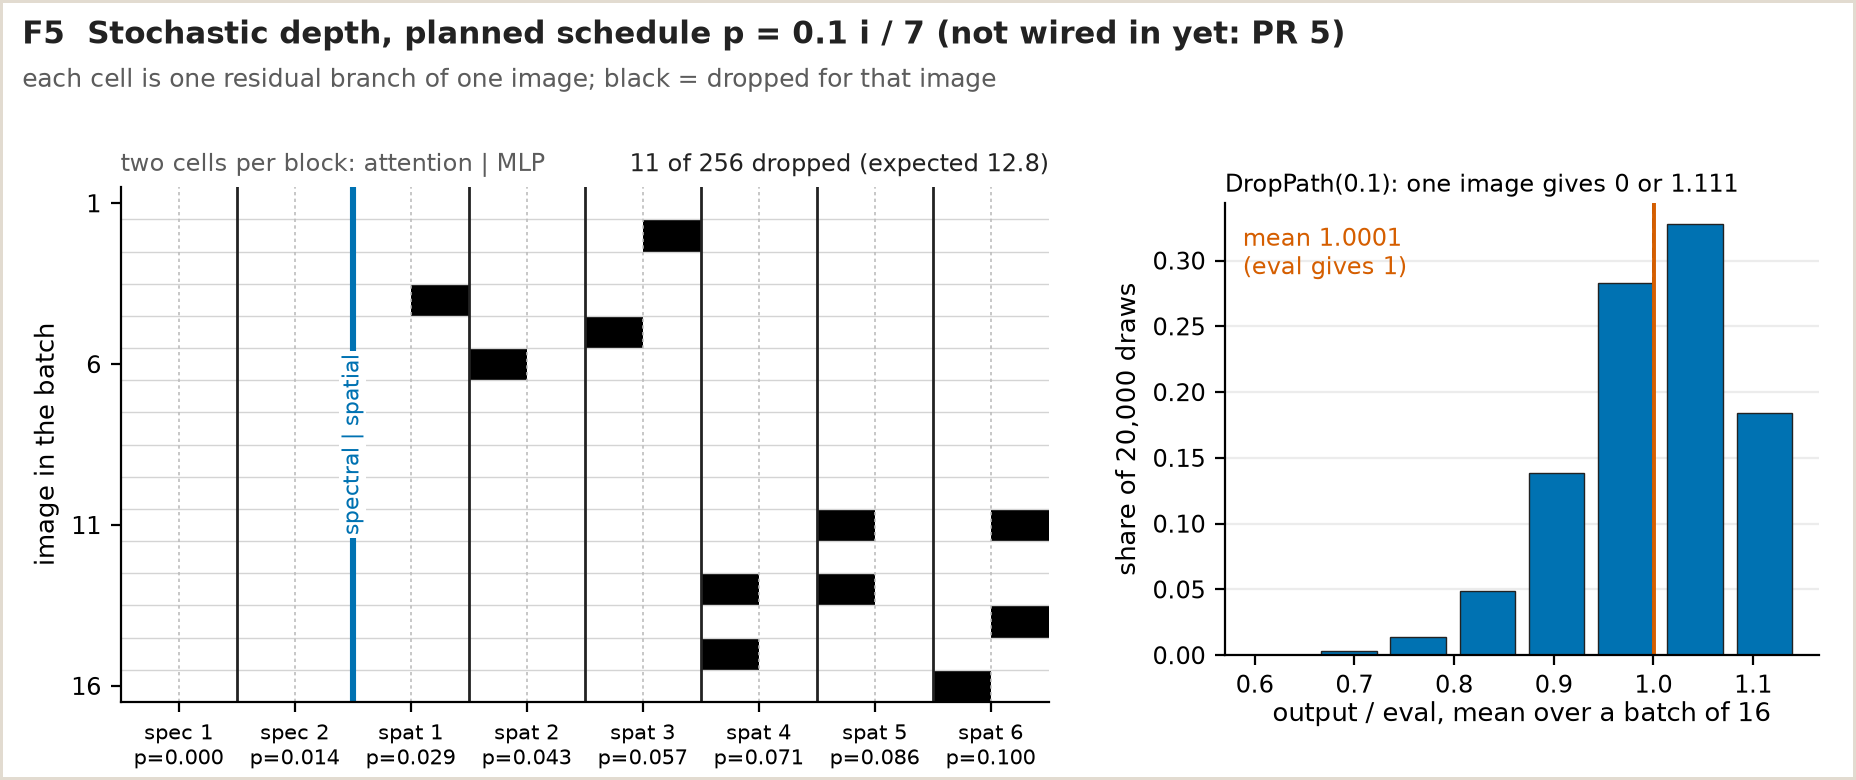

In [8]:
seed_everything()
BLOCKS = ["spec 1", "spec 2"] + [f"spat {i}" for i in range(1, 7)]
P_PLAN = [0.1 * i / 7 for i in range(len(BLOCKS))]
B = 16
dropped = np.zeros((B, len(BLOCKS), 2), dtype=bool)
for i, p in enumerate(P_PLAN):
    drop = DropPath(p).train()
    for branch in range(2):
        dropped[:, i, branch] = (drop(torch.ones(B, 1))[:, 0] == 0).numpy()
expected = 2 * B * sum(P_PLAN)
print("planned p per block:", [round(p, 4) for p in P_PLAN])
print(f"dropped {int(dropped.sum())} of {dropped.size} branch draws (expected {expected:.1f})")

DRAWS, P_LAST = 20_000, P_PLAN[-1]
drop = DropPath(P_LAST).train()
ratios = torch.stack([drop(torch.ones(B, 1)).mean() for _ in range(DRAWS)]).numpy()  # eval output is 1
print(f"DropPath({P_LAST:.1f}), batch {B}, {DRAWS} draws: mean train/eval {ratios.mean():.4f}, sd {ratios.std():.4f}; "
      f"one image is 0 or {1 / (1 - P_LAST):.4f}")

fig = plt.figure(figsize=SLOT_BAND)
fig_title(fig, "F5  Stochastic depth, planned schedule p = 0.1 i / 7 (not wired in yet: PR 5)",
          "each cell is one residual branch of one image; black = dropped for that image")
ax = fig.add_axes([0.065, 0.10, 0.50, 0.66])
grid = dropped.reshape(B, -1).astype(float)  # columns: block 0 attn, block 0 mlp, block 1 attn, ...
ax.imshow(grid, cmap="Greys", vmin=0, vmax=1, aspect="auto")
for yb in np.arange(0.5, B - 1, 1):
    ax.axhline(yb, color="#d4d4d4", lw=0.5)
for k in range(len(BLOCKS)):
    ax.axvline(2 * k + 0.5, color="#bdbdbd", lw=0.6, ls=(0, (2, 2)))  # attention | MLP inside a block
for k in range(1, len(BLOCKS)):
    ax.axvline(2 * k - 0.5, color=C_A if k == 2 else INK, lw=2.2 if k == 2 else 1.0)
ax.set_xticks([2 * k + 0.5 for k in range(len(BLOCKS))], [f"{b}\np={p:.3f}" for b, p in zip(BLOCKS, P_PLAN)], fontsize=7.5)
ax.set_yticks([0, 5, 10, 15], [1, 6, 11, 16])
ax.set_ylabel("image in the batch")
ax.text(0.0, 1.02, "two cells per block: attention | MLP", transform=ax.transAxes, fontsize=8.5, color=MUTED, ha="left", va="bottom")
ax.text(1.0, 1.02, f"{int(dropped.sum())} of {dropped.size} dropped (expected {expected:.1f})", transform=ax.transAxes,
        fontsize=8.5, color=INK, ha="right", va="bottom")
ax.text(4.0 / grid.shape[1], 0.5, "spectral | spatial", transform=ax.transAxes, fontsize=8, color=C_A, ha="center",
        va="center", rotation=90, bbox=dict(facecolor="white", edgecolor="none", pad=1))

ax = fig.add_axes([0.66, 0.16, 0.32, 0.58])
values, counts_ = np.unique(np.round(ratios, 6), return_counts=True)
ax.bar(values, counts_ / DRAWS, width=0.8 / (B * (1 - P_LAST)), color=C_A, edgecolor=INK, linewidth=0.5)
ax.axvline(1.0, color=INK, ls="--", lw=1.0)
ax.axvline(ratios.mean(), color=C_B, lw=1.4)
ax.text(0.03, 0.95, f"mean {ratios.mean():.4f}\n(eval gives 1)", transform=ax.transAxes, color=C_B, fontsize=8.5,
        ha="left", va="top")
ax.set_xlabel(f"output / eval, mean over a batch of {B}", labelpad=1)
ax.set_ylabel(f"share of {DRAWS:,} draws")
ax.set_title(f"DropPath({P_LAST:.1f}): one image gives 0 or {1 / (1 - P_LAST):.3f}", fontsize=8.5, pad=4, loc="left")
ax.grid(axis="y", color=GRID)
ax.set_axisbelow(True)
save(fig, "f5_drop_path_masks")

## F6 (PR 6, control). Shuffle the band groups

**What it shows.** Permute the 14 band groups of the input cube (each group keeps its 16 bands, only the order of the groups changes), 20 random permutations, and record the largest change in any logit, `max |delta logits|`, on a log axis. Three untrained models (eval mode, seed 0): `BandTransformer(0, 2)` (no spectral block: groups go straight to the mean pool), `(1, 1)` and the default `(2, 6)`. The input is the synthetic scene at 64 by 64 px. The "collapsed tokenizer" row is a placeholder for the PR 6 control.

**Takeaway.** Without a spectral block the model is blind to band order: the shared group conv gives each group the same treatment, the learned group embedding is added and then averaged away by the mean pool, so a permutation only reorders a sum, and the change is float32 rounding. With one or more spectral blocks the group embedding meets the content inside attention, and order matters.

**Mirrors** no test yet; the closest is the permutation check in `test_spatial_block_attends_across_tokens`, which is the same idea on the spatial axis.

**Could mislead.** Sensitivity at init is not trained behaviour: at init the change is small next to the logits (printed below). A trained spectral block may use band order a lot, or very little; only a trained checkpoint can say.

BandTransformer(0, 2): max |delta logits| over 20 permutations 5.96e-08 .. 8.94e-08 (median 7.45e-08); max |logit| 0.202
BandTransformer(1, 1): max |delta logits| over 20 permutations 2.12e-05 .. 5.02e-05 (median 3.34e-05); max |logit| 0.202


BandTransformer(2, 6): max |delta logits| over 20 permutations 2.13e-05 .. 5.78e-05 (median 3.11e-05); max |logit| 0.152
saved docs/figures/model/f6_shuffle_test.png


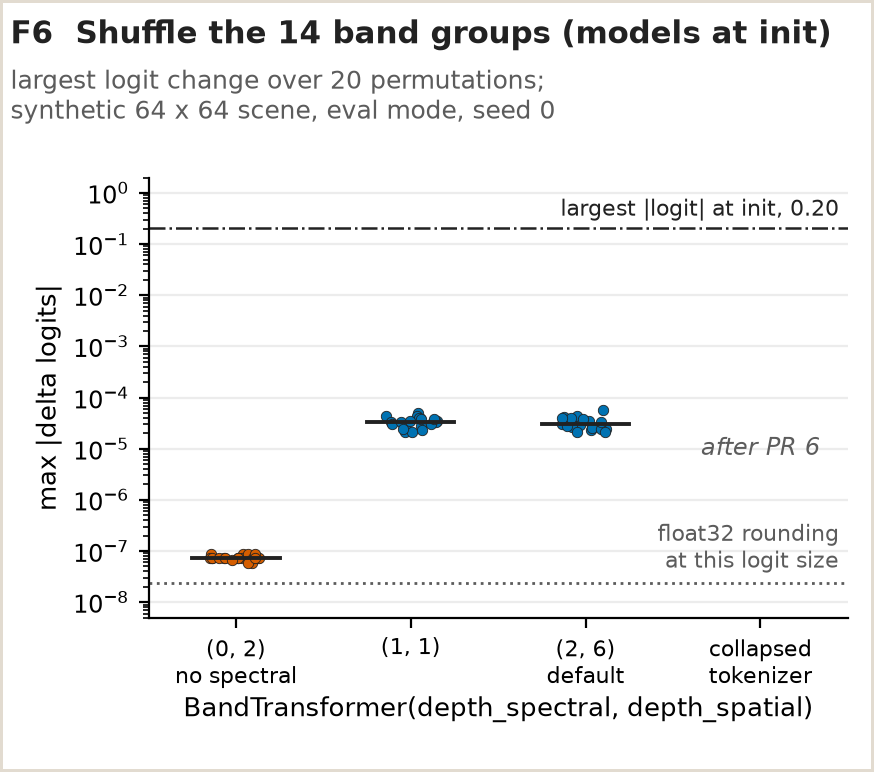

In [9]:
seed_everything()
scene, _ = synthetic_scene(SEED)
x6 = torch.from_numpy(scene[:, ::4, ::4].copy())[None]  # (1, 224, 64, 64)
gen = torch.Generator().manual_seed(SEED)
perms = []
while len(perms) < 20:
    perm = torch.randperm(N_GROUPS, generator=gen)
    if not torch.equal(perm, torch.arange(N_GROUPS)):
        perms.append(perm)


def shuffle_groups(x, perm):
    b, c, h, w = x.shape
    return x.reshape(b, N_GROUPS, GROUP, h, w)[:, perm].reshape(b, c, h, w)


CONFIGS = [(0, 2), (1, 1), (2, 6)]
shuffle = {}
for ds_, dp_ in CONFIGS:
    seed_everything()
    model = BandTransformer(ds_, dp_).eval()
    with torch.no_grad():
        base = model(x6)
        deltas = np.array([(model(shuffle_groups(x6, p)) - base).abs().max().item() for p in perms])
    shuffle[(ds_, dp_)] = (deltas, base.abs().max().item())
    print(f"BandTransformer({ds_}, {dp_}): max |delta logits| over 20 permutations "
          f"{deltas.min():.2e} .. {deltas.max():.2e} (median {np.median(deltas):.2e}); max |logit| {base.abs().max():.3f}")
eps_floor = np.finfo(np.float32).eps * max(v[1] for v in shuffle.values())

fig, ax = plt.subplots(figsize=SLOT_CHART)
fig.subplots_adjust(left=0.17, right=0.97, top=0.77, bottom=0.20)
fig_title(fig, "F6  Shuffle the 14 band groups (models at init)",
          "largest logit change over 20 permutations;\nsynthetic 64 x 64 scene, eval mode, seed 0")
rng = np.random.default_rng(SEED)
for k, cfg_ in enumerate(CONFIGS):
    deltas, _ = shuffle[cfg_]
    ax.scatter(k + rng.uniform(-0.15, 0.15, len(deltas)), deltas, s=14, color=C_A if cfg_[0] else C_B,
               edgecolor=INK, linewidth=0.3, zorder=3)
    ax.plot([k - 0.25, k + 0.25], [np.median(deltas)] * 2, color=INK, lw=1.4, zorder=4)
ax.text(3, 1e-5, "after PR 6", ha="center", va="center", fontsize=8.5, color=MUTED, style="italic")
logit_max = max(v[1] for v in shuffle.values())
ax.axhline(logit_max, color=INK, ls="-.", lw=0.9)
ax.text(3.45, logit_max * 1.4, f"largest |logit| at init, {logit_max:.2f}", ha="right", va="bottom", fontsize=8, color=INK)
ax.axhline(eps_floor, color=MUTED, ls=":", lw=1)
ax.text(3.45, eps_floor * 1.4, "float32 rounding\nat this logit size", ha="right", va="bottom", fontsize=8, color=MUTED)
ax.set_yscale("log")
ax.set_ylim(5e-9, 2)
ax.set_xlim(-0.5, 3.5)
ax.set_xticks(range(4), ["(0, 2)\nno spectral", "(1, 1)", "(2, 6)\ndefault", "collapsed\ntokenizer"], fontsize=8)
ax.set_xlabel("BandTransformer(depth_spectral, depth_spatial)", labelpad=2)
ax.set_ylabel("max |delta logits|")
ax.grid(axis="y", color=GRID)
ax.set_axisbelow(True)
save(fig, "f6_shuffle_test")

## F7 (design finding). "What shape" is easy, "which band" is not

**What it shows.** The default `BandTransformer(2, 6)` trained with Adam (lr 1e-3, `F7_STEPS` steps, default 300) on two synthetic tasks built like `_learnable_batch` in `tests/test_transformer.py`: 4 images of 32 by 32 px, one class per 8 by 8 patch, noise `0.05 * U(0, 1)` on every band.

* **(a) shape:** class `c` adds a fixed 16-band spectral shape, repeated in all 14 groups (exactly the test's batch; the cell checks this when pytest is installed).
* **(b) position:** class `c` adds 0.5 to bands `32c .. 32c + 31`, so the class is *which pair of band groups is bright*. Every group looks like either "bright" or "dim"; only its position says which class it is.

Pixel accuracy (all pixels, boundaries included; chance is 1/7) is tracked for 2 seeds. Left: one fixed batch, as in the test, scored on that batch (solid) and on a held-out batch made the same way (dotted). Right: a fresh batch every step, scored on the held-out batch.

**Measured elsewhere (task spec, CPU, fixed batch):** at 100 steps (a) 93 to 95% vs (b) 37 to 52%; both about 96 to 100% by 300.

**This run (CPU, 300 steps, printed below)** agrees on the fixed batch: at step 100, (a) 92.5 and 95.4% vs (b) 44.4 and 46.9%; at step 300, (a) 98.9 and 99.8%, (b) 96.2 and 98.8%. **The held-out curves change the reading.** On a held-out batch, task (b) ends at 20.9 and 25.3% (chance is 14.3%): the fixed batch was memorised, not learned. Trained on a fresh batch every step, task (b) stays at chance (6.5 and 17.2% at step 300, loss 1.946 and 1.947, which is `ln 7`), while task (a) reaches 94.2 and 95.0% held-out. *Measured outside this notebook:* 1500 fresh-batch steps of task (b), seed 0, left the loss at 1.95 the whole way.

**Takeaway.** The tokenizer's group conv is shared, so it sees *what shape* a group has but not *where* the group sits. Only the learned group embedding carries position, and it reaches the content only inside spectral attention and the MLP; the mean pool then averages over groups. For real data this matters: an absorption feature at 1200 nm and the same feature at 1450 nm look alike to the conv.

**Mirrors** `test_band_transformer_learns_a_synthetic_task` (task a, 120 steps, `(1, 1)` model) and the `_learnable_batch` docstring, which predicts task (b) is "much harder for this design".

**Could mislead.** Two synthetic tasks, two seeds, one learning rate, a short budget, CPU. "Not learned in 300 steps" is not "cannot be learned"; a longer run, a different lr or a position-aware tokenizer could change it. With `F7_STEPS` below 300 the curves stop early. GPU runs differ slightly from CPU.

task (a) matches tests/test_transformer.py::_learnable_batch(0) exactly


8 runs of 300 steps in 70 s on cpu
step  100  (a) shape    seed 0  fixed batch  95.4%, held-out  78.2%  loss 0.157
step  100  (a) shape    seed 1  fixed batch  92.5%, held-out  83.0%  loss 0.204
step  100  (b) position seed 0  fixed batch  46.9%, held-out  12.5%  loss 1.273
step  100  (b) position seed 1  fixed batch  44.4%, held-out  10.2%  loss 1.315
step  100  (a) shape    seed 0  fresh batches, held-out  82.2%  loss 0.549
step  100  (a) shape    seed 1  fresh batches, held-out  86.1%  loss 0.493
step  100  (b) position seed 0  fresh batches, held-out   6.2%  loss 1.940
step  100  (b) position seed 1  fresh batches, held-out   9.7%  loss 1.943
step  300  (a) shape    seed 0  fixed batch  99.8%, held-out  80.7%  loss 0.020
step  300  (a) shape    seed 1  fixed batch  98.9%, held-out  85.6%  loss 0.045
step  300  (b) position seed 0  fixed batch  98.8%, held-out  25.3%  loss 0.071
step  300  (b) position seed 1  fixed batch  96.2%, held-out  20.9%  loss 0.103
step  300  (a) shape    s

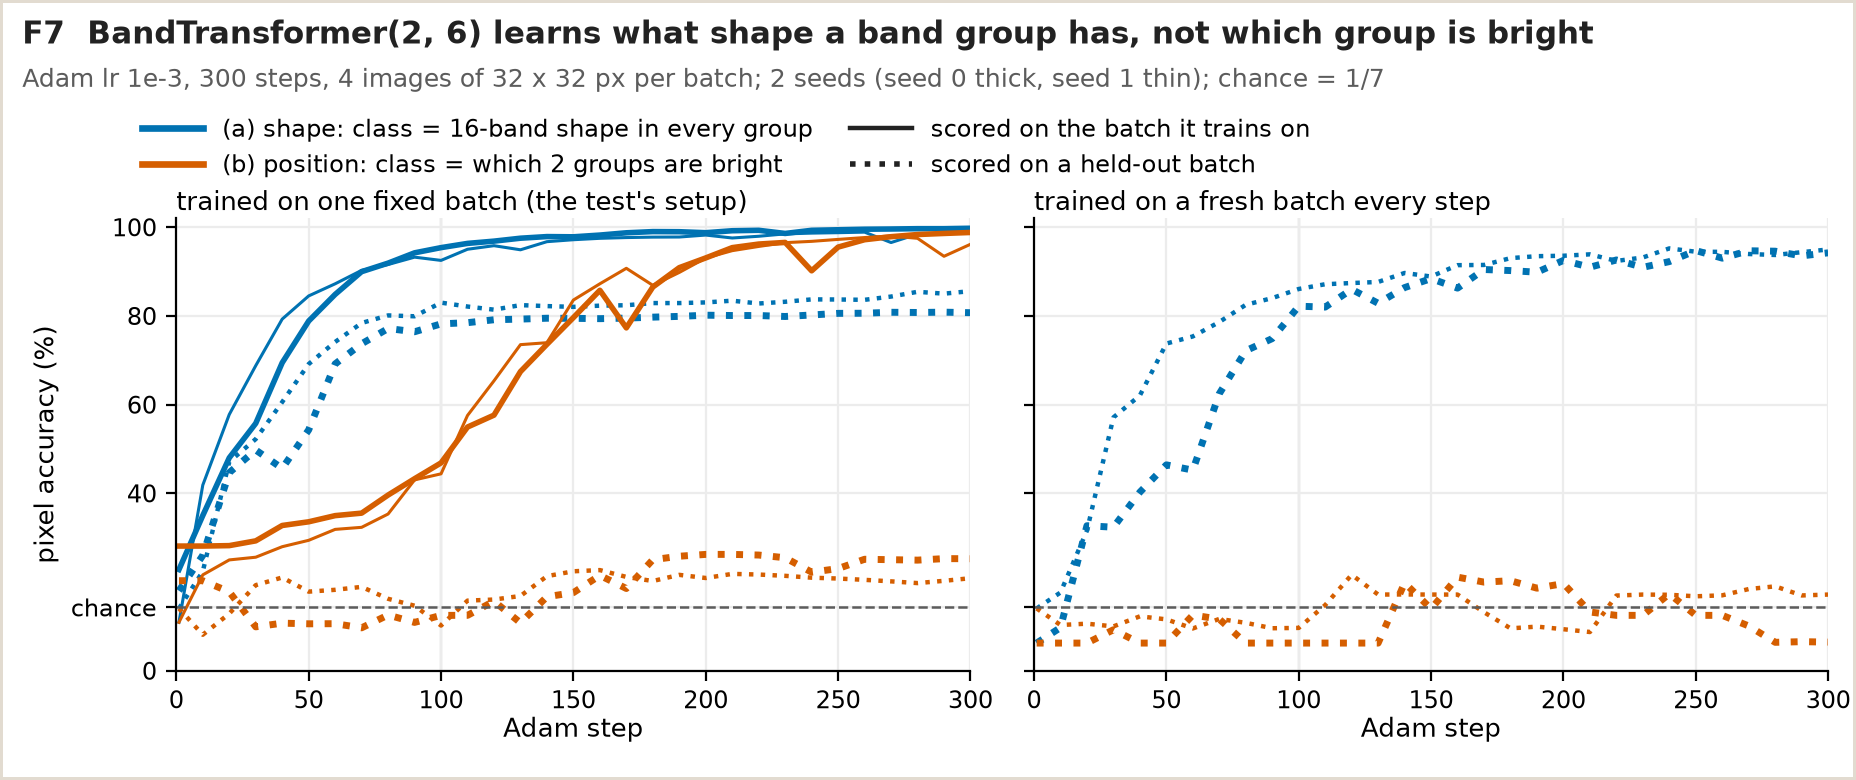

In [10]:
seed_everything()
SHAPES = torch.rand(7, 16, generator=torch.Generator().manual_seed(123))  # the test's class shapes
BAND_CLASS = torch.arange(N_BANDS) // 32  # task b: class c brightens bands 32c .. 32c + 31
EVAL_EVERY = 10


def task_batch(task, seed, n=4):
    """Built like tests/test_transformer.py::_learnable_batch: same generator order, same noise."""
    g = torch.Generator().manual_seed(seed)
    labels = torch.randint(0, 7, (n, 4, 4), generator=g)  # one class per 8 by 8 patch
    x = 0.05 * torch.rand(n, N_BANDS, 32, 32, generator=g)
    y = labels.repeat_interleave(8, 1).repeat_interleave(8, 2)
    if task == "shape":
        signal = SHAPES.repeat(1, 14)[y]  # (n, 32, 32, 224)
    else:
        signal = 0.5 * (BAND_CLASS == y[..., None]).float()
    return x + signal.permute(0, 3, 1, 2), y


try:  # cross-check task (a) against the test's own batch
    import importlib.util

    spec = importlib.util.spec_from_file_location("test_transformer", REPO / "tests" / "test_transformer.py")
    test_mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(test_mod)
    xt, yt = test_mod._learnable_batch(0)
    xa, ya = task_batch("shape", 0)
    assert torch.equal(ya, yt) and torch.allclose(xa, xt), "task (a) differs from _learnable_batch"
    print("task (a) matches tests/test_transformer.py::_learnable_batch(0) exactly")
except ImportError as err:
    print(f"cross-check skipped ({err}); install pytest to run it")


def accuracy(model, x, y):
    model.eval()
    with torch.no_grad():
        return (model(x).argmax(1) == y).float().mean().item()


def train_run(task, seed, fresh, steps=F7_STEPS):
    seed_everything(seed)
    model = BandTransformer(2, 6).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    x_fit, y_fit = (t.to(DEVICE) for t in task_batch(task, seed))
    x_val, y_val = (t.to(DEVICE) for t in task_batch(task, 1000 + seed))
    curve = []
    for step in range(1, steps + 1):
        if fresh:
            x, y = (t.to(DEVICE) for t in task_batch(task, 10_000 * (seed + 1) + step))
        else:
            x, y = x_fit, y_fit
        model.train()
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad()
        loss.backward()
        opt.step()
        if step % EVAL_EVERY == 0 or step == 1:
            curve.append((step, accuracy(model, x_fit, y_fit), accuracy(model, x_val, y_val), loss.item()))
    return np.array(curve)


t0 = time.time()
runs = {}
for fresh in (False, True):
    for task in ("shape", "position"):
        for seed in (0, 1):
            runs[(fresh, task, seed)] = train_run(task, seed, fresh)
print(f"{len(runs)} runs of {F7_STEPS} steps in {time.time() - t0:.0f} s on {DEVICE}")
for step_mark in sorted({min(100, F7_STEPS), F7_STEPS}):
    for (fresh, task, seed), c in runs.items():
        row = c[c[:, 0] == step_mark][0]
        what = "fresh batches, held-out" if fresh else f"fixed batch {row[1]:6.1%}, held-out"
        print(f"step {step_mark:4d}  ({'a' if task == 'shape' else 'b'}) {task:8s} seed {seed}  {what} {row[2]:6.1%}  loss {row[3]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=SLOT_BAND, sharey=True)
fig.subplots_adjust(left=0.095, right=0.985, top=0.72, bottom=0.14, wspace=0.08)
fig_title(fig, "F7  BandTransformer(2, 6) learns what shape a band group has, not which group is bright",
          f"Adam lr 1e-3, {F7_STEPS} steps, 4 images of 32 x 32 px per batch; 2 seeds (seed 0 thick, seed 1 thin); chance = 1/7")
for ax, fresh in zip(axes, (False, True)):
    for task, color in (("shape", C_A), ("position", C_B)):
        for seed in (0, 1):
            c = runs[(fresh, task, seed)]
            lw = 2.0 if seed == 0 else 1.1
            name = "(a) shape" if task == "shape" else "(b) position"
            if not fresh:
                ax.plot(c[:, 0], c[:, 1] * 100, "-", color=color, lw=lw)
            ax.plot(c[:, 0], c[:, 2] * 100, ":", color=color, lw=lw + 0.5)
    ax.axhline(100 / 7, color=MUTED, ls="--", lw=0.9)
    ax.set_yticks([0, 100 / 7, 40, 60, 80, 100], ["0", "chance", "40", "60", "80", "100"])
    if F7_STEPS >= 100:
        ax.axvline(100, color="#bbbbbb", lw=0.8, zorder=0)
    ax.set_xlim(0, F7_STEPS)
    ax.set_ylim(0, 102)
    ax.set_xlabel("Adam step", labelpad=1)
    ax.grid(color=GRID)
    ax.set_axisbelow(True)
    ax.set_title("trained on one fixed batch (the test's setup)" if not fresh else "trained on a fresh batch every step",
                 fontsize=9.5, loc="left", pad=3)
axes[0].set_ylabel("pixel accuracy (%)")
from matplotlib.lines import Line2D

legend_items = [
    Line2D([], [], color=C_A, lw=2.4, label="(a) shape: class = 16-band shape in every group"),
    Line2D([], [], color=C_B, lw=2.4, label="(b) position: class = which 2 groups are bright"),
    Line2D([], [], color=INK, lw=1.6, ls="-", label="scored on the batch it trains on"),
    Line2D([], [], color=INK, lw=2.0, ls=":", label="scored on a held-out batch"),
]
fig.legend(handles=legend_items, loc="upper left", bbox_to_anchor=(0.065, 0.875), ncol=2, frameon=False, fontsize=8.5,
           columnspacing=1.6, handlelength=2.6)
save(fig, "f7_shape_vs_position")

## F8 (PR 9). Memory against token count

**What it shows.** Activation memory that autograd keeps for the backward pass, for the default encoder (6 spatial blocks, 2 spectral blocks, 4 heads, D = 64, float32) at batch 8, against the number of spatial tokens `N` (patch 8 at full resolution is `N = 1024`; `--downsample 2` gives 256; patch 4 would give 4096). Lines: the closed form for the attention maps alone. A spatial block attends over `N` tokens, so it keeps `B * H * N^2` per map; a spectral block attends over `G = 14` groups inside each of the `N` tokens, `B * N * H * G^2`. Autograd keeps **two** such maps per block: the softmax output and the `nan_to_num` copy that `sw.attention` makes of it. Markers: measured, with `torch.autograd.graph.saved_tensors_hooks` on one block at batch 1, counting each storage once, then scaled by batch and block count. The dashed line is a 16 GB T4.

**Takeaway.** The two `N^2` maps are most of what a spatial block keeps from `N = 256` on, and almost all of it at `N = 1024` (two 16 MiB maps per image, out of about 36 MiB); they are what makes patch 4 too big. But the spectral attention maps are small, and the spectral *blocks* are not: each keeps more than a spatial block at `N = 1024`, because it runs its MLP and norms on 14 times as many tokens. The `N^2` story is the spatial blocks only.

**Mirrors** the cost paragraph of the `SpatialBlock` docstring (two 16 MiB tensors, about 36 MiB per image per block, about 1.7 GiB for six blocks at batch 8); no test.

**Could mislead.** Encoder blocks only: the tokenizer, the head (32 channels at full resolution), the weights, the optimiser state and the CUDA allocator's slack are not here, so the real peak is higher. fp16 autocast halves most of it. Measured on CPU; CUDA kernels can save different intermediates.

N =    64: spatial block keeps    0.56 MiB per image, 2 (H, N, N) maps of   0.06 MiB; spectral block    4.08 MiB, 2 (N, H, G, G) maps of  0.19 MiB
           the two (H, N, N) maps are 22% of the spatial block's total
N =   256: spatial block keeps    3.19 MiB per image, 2 (H, N, N) maps of   1.00 MiB; spectral block   15.77 MiB, 2 (N, H, G, G) maps of  0.77 MiB
           the two (H, N, N) maps are 63% of the spatial block's total
N =  1024: spatial block keeps   36.20 MiB per image, 2 (H, N, N) maps of  16.00 MiB; spectral block   62.53 MiB, 2 (N, H, G, G) maps of  3.06 MiB
           the two (H, N, N) maps are 88% of the spatial block's total


N =  4096: spatial block keeps  528.25 MiB per image, 2 (H, N, N) maps of 256.00 MiB; spectral block  249.56 MiB, 2 (N, H, G, G) maps of 12.25 MiB
           the two (H, N, N) maps are 97% of the spatial block's total
batch 8, N = 1024: spatial maps 1.50 GiB, measured spatial blocks 1.70 GiB, spectral blocks 0.98 GiB
saved docs/figures/model/f8_memory_vs_tokens.png


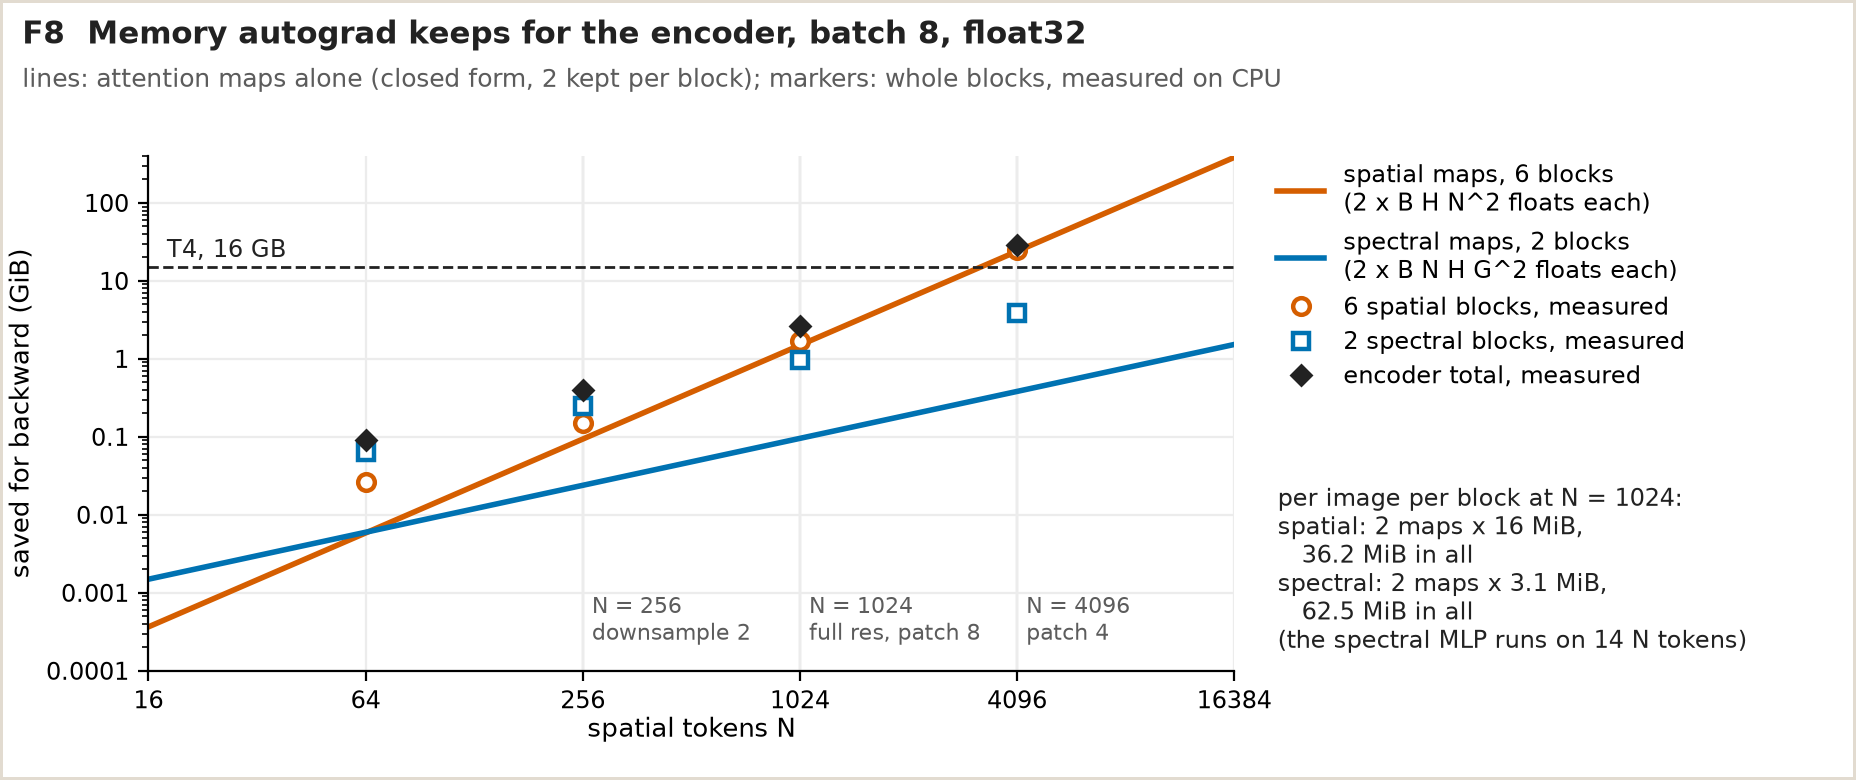

In [11]:
seed_everything()
H_, D_, G_, B_ = 4, 64, N_GROUPS, 8
N_SPATIAL, N_SPECTRAL = 6, 2
MiB, GiB = 2**20, 2**30


def saved_storages(module, x):
    """Bytes of every storage autograd saves during one forward, each storage counted once."""
    seen, shapes = {}, {}

    def pack(t):
        s = t.untyped_storage()
        seen[s.data_ptr()] = max(seen.get(s.data_ptr(), 0), s.nbytes())
        shapes.setdefault(s.data_ptr(), set()).add(tuple(t.shape))
        return t

    with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t):
        module(x)
    return seen, shapes


def n_attention_maps(seen, shapes, n_seq, heads, length):
    """How many distinct storages hold attention weights: n_seq * heads maps of length x length floats,
    saved as some view whose last two axes are (length, length). matmul may save a reshaped view."""
    size = 4 * n_seq * heads * length * length
    return sum(seen[k] == size and any(sh[-2:] == (length, length) for sh in shapes[k]) for k in seen)


MEASURE_N = [64, 256, 1024, 4096]
measured = {"spatial": {}, "spectral": {}}
for n in MEASURE_N:
    sp, sp_shapes = saved_storages(SpatialBlock(D_, H_), torch.randn(1, n, D_, requires_grad=True))
    sc, sc_shapes = saved_storages(SpectralBlock(D_, H_), torch.randn(1, n, G_, D_, requires_grad=True))
    measured["spatial"][n] = sum(sp.values())
    measured["spectral"][n] = sum(sc.values())
    n_sp, n_sc = n_attention_maps(sp, sp_shapes, 1, H_, n), n_attention_maps(sc, sc_shapes, n, H_, G_)
    print(f"N = {n:5d}: spatial block keeps {sum(sp.values()) / MiB:7.2f} MiB per image, "
          f"{n_sp} (H, N, N) maps of {4 * H_ * n * n / MiB:6.2f} MiB; "
          f"spectral block {sum(sc.values()) / MiB:7.2f} MiB, {n_sc} (N, H, G, G) maps of {4 * n * H_ * G_**2 / MiB:5.2f} MiB")
    assert n_sp == 2 and n_sc == 2
    print(f"           the two (H, N, N) maps are {2 * 4 * H_ * n * n / sum(sp.values()):.0%} of the spatial block's total")

Ns = np.logspace(np.log10(16), np.log10(16384), 200)
spatial_maps = N_SPATIAL * 2 * B_ * H_ * Ns**2 * 4
spectral_maps = N_SPECTRAL * 2 * B_ * Ns * H_ * G_**2 * 4
T4 = 16e9
print(f"batch {B_}, N = 1024: spatial maps {N_SPATIAL * 2 * B_ * H_ * 1024**2 * 4 / GiB:.2f} GiB, "
      f"measured spatial blocks {N_SPATIAL * B_ * measured['spatial'][1024] / GiB:.2f} GiB, "
      f"spectral blocks {N_SPECTRAL * B_ * measured['spectral'][1024] / GiB:.2f} GiB")

fig, ax = plt.subplots(figsize=SLOT_BAND)
fig.subplots_adjust(left=0.08, right=0.665, top=0.80, bottom=0.14)
fig_title(fig, "F8  Memory autograd keeps for the encoder, batch 8, float32",
          "lines: attention maps alone (closed form, 2 kept per block); markers: whole blocks, measured on CPU")
ax.plot(Ns, spatial_maps / GiB, "-", color=C_B, lw=2, label="spatial maps, 6 blocks\n(2 x B H N^2 floats each)")
ax.plot(Ns, spectral_maps / GiB, "-", color=C_A, lw=2, label="spectral maps, 2 blocks\n(2 x B N H G^2 floats each)")
ms = np.array(MEASURE_N, dtype=float)
sp_tot = np.array([measured["spatial"][n] for n in MEASURE_N]) * B_ * N_SPATIAL
sc_tot = np.array([measured["spectral"][n] for n in MEASURE_N]) * B_ * N_SPECTRAL
ax.plot(ms, sp_tot / GiB, "o", ms=6, mfc="white", mec=C_B, mew=1.6, label="6 spatial blocks, measured")
ax.plot(ms, sc_tot / GiB, "s", ms=6, mfc="white", mec=C_A, mew=1.6, label="2 spectral blocks, measured")
ax.plot(ms, (sp_tot + sc_tot) / GiB, "D", ms=5, color=INK, label="encoder total, measured")
ax.axhline(T4 / GiB, color=INK, ls="--", lw=1)
ax.text(18, T4 / GiB * 1.15, "T4, 16 GB", fontsize=8.5, color=INK, va="bottom")
for n, text in ((256, "N = 256\ndownsample 2"), (1024, "N = 1024\nfull res, patch 8"), (4096, "N = 4096\npatch 4")):
    ax.axvline(n, color="#bbbbbb", lw=0.8, zorder=0)
    ax.text(n * 1.06, 2e-4, text, fontsize=8, color=MUTED, va="bottom", ha="left")
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks([16, 64, 256, 1024, 4096, 16384])
plain_log_ticks(ax.xaxis)
plain_log_ticks(ax.yaxis)
ax.set_xlim(16, 16384)
ax.set_ylim(1e-4, 400)
ax.set_xlabel("spatial tokens N", labelpad=1)
ax.set_ylabel("saved for backward (GiB)")
ax.grid(color=GRID, which="major")
ax.set_axisbelow(True)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.03), frameon=False, fontsize=8.5, labelspacing=0.45)
n1 = 1024
ax.text(1.04, 0.36,
        f"per image per block at N = {n1}:\n"
        f"spatial: 2 maps x {4 * H_ * n1 * n1 / MiB:.0f} MiB,\n   {measured['spatial'][n1] / MiB:.1f} MiB in all\n"
        f"spectral: 2 maps x {4 * n1 * H_ * G_**2 / MiB:.1f} MiB,\n   {measured['spectral'][n1] / MiB:.1f} MiB in all\n"
        "(the spectral MLP runs on 14 N tokens)",
        transform=ax.transAxes, fontsize=8.5, color=INK, va="top", ha="left")
save(fig, "f8_memory_vs_tokens")

## F9 (training logs). Curves and per-class IoU from `metrics.jsonl`

**What it shows.** For each file in `TRAIN_LOG`: train loss per epoch, foreground mIoU per epoch (val, and train when the log has `train_fg_miou`, which the overfit gate needs and a later PR adds), and per-class val IoU at the best val epoch, coloured by the class palette.

**Takeaway.** Depends on the run. For the overfit gate, train mIoU should climb toward 1 on its few images while val tells you nothing; for a real run, read the per-class bars against the paper's row.

**Mirrors** `test_transformer_smoke` (the `metrics.jsonl` columns `epoch`, `train_loss`, `val_fg_miou`, `steps`, `per_class_iou`).

**Could mislead.** One run per file, no error bars. A val mIoU from a handful of val images (`--max-val-images`) is noisy, and a class absent from val has no IoU (drawn as "n/a", not 0).

In [12]:
def read_log(path):
    rows = [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]
    if not rows:
        raise ValueError(f"{path} is empty")
    return rows


if not TRAIN_LOGS:
    skip("F9", "TRAIN_LOG not set (point it at a metrics.jsonl written by sw.train)")
else:
    logs = {}
    for path in TRAIN_LOGS:
        try:
            logs[f"{path.parent.name}/{path.name}"] = read_log(path)
        except (OSError, ValueError, json.JSONDecodeError) as err:
            print(f"cannot read {path}: {err}")
    if not logs:
        skip("F9", "no readable TRAIN_LOG")
    else:
        fig, (ax_l, ax_m, ax_c) = plt.subplots(1, 3, figsize=SLOT_BAND, gridspec_kw={"width_ratios": [1, 1, 1.25], "wspace": 0.32})
        fig.subplots_adjust(left=0.07, right=0.99, top=0.78, bottom=0.19)
        fig_title(fig, "F9  Training log" + ("s" if len(logs) > 1 else ""), ", ".join(logs))
        styles = [("-", INK), ("--", C_A), (":", C_B)]
        best_rows = {}
        for (name, rows), (ls, color) in zip(logs.items(), styles):
            ep = np.array([r["epoch"] for r in rows])
            ax_l.plot(ep, [r["train_loss"] for r in rows], ls, color=color, lw=1.8, marker="o", ms=3, label=name)
            val = np.array([np.nan if r.get("val_fg_miou") is None else 100 * r["val_fg_miou"] for r in rows])
            ax_m.plot(ep, val, ls, color=color, lw=1.8, marker="o", ms=3, label=f"val, {name}")
            if any(r.get("train_fg_miou") is not None for r in rows):
                tr = np.array([np.nan if r.get("train_fg_miou") is None else 100 * r["train_fg_miou"] for r in rows])
                ax_m.plot(ep, tr, ls, color=color, lw=1.0, alpha=0.7, label=f"train, {name}")
            if np.isfinite(val).any():
                b = int(np.nanargmax(val))
                best_rows[name] = rows[b]
                ax_m.scatter([ep[b]], [val[b]], s=30, color=color, zorder=3)
                print(f"{name}: {len(rows)} epochs, best val FG mIoU {val[b]:.1f}% at epoch {ep[b]}")
            else:
                print(f"{name}: {len(rows)} epochs, no val FG mIoU")
        has_train = any(r.get("train_fg_miou") is not None for rows in logs.values() for r in rows)
        if not has_train:
            ax_m.text(0.98, 0.04, "no train_fg_miou in this log\n(the overfit gate adds it)", transform=ax_m.transAxes,
                      ha="right", va="bottom", fontsize=8, color=MUTED)
        for a, lab in ((ax_l, "train loss"), (ax_m, "FG mIoU (%)")):
            a.set_xlabel("epoch", labelpad=1)
            a.set_ylabel(lab)
            a.grid(color=GRID)
            a.set_axisbelow(True)
        ax_m.set_ylim(0, 100)
        ax_m.legend(loc="upper left", frameon=False, fontsize=7.5)
        if best_rows:
            name, row = next(iter(best_rows.items()))
            per = row.get("per_class_iou") or {}
            ys = np.arange(len(OBJECT_CLASSES))[::-1]
            for yv, cname in zip(ys, OBJECT_CLASSES):
                v = per.get(cname)
                if v is None:
                    ax_c.text(1, yv, "n/a (absent in val)", va="center", fontsize=8, color=MUTED)
                    continue
                ax_c.barh(yv, 100 * v, color=COLOR[cname], edgecolor=INK, linewidth=0.7, height=0.62)
                ax_c.text(100 * v + 1.5, yv, f"{100 * v:.1f}", va="center", fontsize=8.5, color=INK)
            ax_c.set_yticks(ys, [LABEL[c] for c in OBJECT_CLASSES])
            ax_c.set_xlim(0, 105)
            ax_c.set_xlabel("val IoU (%)", labelpad=1)
            ax_c.set_title(f"best epoch {row['epoch']}, {name}", fontsize=8.5, loc="left", pad=3)
            ax_c.grid(axis="x", color=GRID)
            ax_c.set_axisbelow(True)
        else:
            ax_c.axis("off")
        save(fig, "f9_training_log")

SKIP F9: TRAIN_LOG not set (point it at a metrics.jsonl written by sw.train)


## F10 (trained). Spectral attention across band groups, per object class

**What it shows.** For a trained checkpoint, the attention weights inside the last spectral block (`model.spectral[-1].attn_block.attn`, hooked), a 14 by 14 matrix per patch: row = the query band group, column = the key group it reads from, averaged over heads. A patch goes to the object class with the most pixels in it if that class covers at least 1/8 of the patch (a 1 px line across an 8 px patch is exactly 1/8); a strict majority would leave filament and tape with no patches at all. The matrices are averaged per class over the val images, one panel per object class, on one log colour scale (weight times 14; 1 = uniform). Right: how much each key group is read, averaged over query groups, one line per class (background dotted). Axis ticks are the nominal centre wavelengths of the groups (even spacing over 900 to 1700 nm is assumed; `meta.json` ships no wavelengths).

**Takeaway.** Depends on the checkpoint: look for key groups that every class reads (columns that light up in all panels) against groups only one class reads, and compare the latter with the class spectra in notebook 04, cell D. If the lines on the right lie on top of each other, the spectral attention follows band position (the group embedding), not the material.

**Mirrors** no test; F6 is the init-time control for whether band order can matter at all.

**Could mislead.** Same guard as F2: attention is not attribution. A class average hides variation between patches, the majority rule mixes boundary patches into a class, and rare classes (filament) get few patches (the count is printed per panel). A patch with 1/8 filament is still 7/8 something else, so the thin-class panels mix in their surroundings. With `--downsample 2` the strided mask can drop a 1 px line altogether.

In [13]:
F10_MAX_IMAGES = int(os.environ.get("F10_MAX_IMAGES", "24"))
F10_MIN_SHARE = 1 / 8  # a 1 px line across an 8 px patch covers exactly 1/8 of it
if CKPT is None or SW_ROOT is None:
    skip("F10", "needs both CKPT and SW_ROOT (" + ", ".join(n for n, v in (("CKPT", CKPT), ("SW_ROOT", SW_ROOT)) if v is None) + " not set)")
else:
    model = trained_model()
    _, cfg, _ = load_ckpt()
    if model.depth_spectral == 0:
        skip("F10", "this checkpoint has no spectral blocks")
    else:
        try:
            val_ds = SpectralWasteDataset(SW_ROOT, split="val")
        except (FileNotFoundError, ValueError) as err:
            val_ds = None
            skip("F10", f"no usable val split under SW_ROOT ({err})")
        if val_ds is not None:
            ds_factor = int(cfg.get("downsample", 1) or 1)
            patch = int(cfg.get("patch", PATCH))
            G = model.tokenizer.n_groups
            store = {}
            handle = model.spectral[-1].attn_block.attn.register_forward_hook(lambda m, a, o: store.update(w=o[1].detach()))
            sums = np.zeros((len(CLASS_NAMES), G, G))
            n_patches = np.zeros(len(CLASS_NAMES), dtype=int)
            n_img = min(len(val_ds), F10_MAX_IMAGES)
            try:
                for index in range(n_img):
                    cube, mask = val_ds[index]
                    x, m = prepare_sample(cube, mask, train=False, crop_size=None, downsample=ds_factor)
                    with torch.no_grad():
                        model(x[None])
                    w = store["w"].mean(1).numpy()  # (N, G, G), mean over heads
                    gh, gw = x.shape[1] // patch, x.shape[2] // patch
                    _, _, counts = patch_labels(m.numpy(), patch, gh, gw)
                    obj = counts[:, 1:].argmax(1) + 1  # the most common object class in the patch
                    share = counts[np.arange(len(obj)), obj] / (patch * patch)
                    label = np.where(share >= F10_MIN_SHARE, obj, np.where(counts[:, 0] == patch * patch, 0, -1))
                    for c in range(len(CLASS_NAMES)):
                        sel = label == c
                        sums[c] += w[sel].sum(0)
                        n_patches[c] += int(sel.sum())
            finally:
                handle.remove()
            print(f"{n_img} val images, downsample {ds_factor}; patches per class: "
                  + ", ".join(f"{LABEL[n]} {k}" for n, k in zip(CLASS_NAMES, n_patches)))
            means = {c: sums[c] / n_patches[c] for c in range(len(CLASS_NAMES)) if n_patches[c]}
            vals = np.concatenate([means[c].ravel() for c in means if c]) * G if any(means) else np.array([1.0])
            R = float(max(2.0, vals.max(), 1 / max(vals.min(), 1e-6)))
            norm = LogNorm(vmin=1 / R, vmax=R)
            ticks = [0, 7, 13]
            tick_labels = [f"{group_nm(t):.0f}" for t in ticks]

            fig = plt.figure(figsize=SLOT_BAND)
            fig_title(fig, f"F10  Spectral attention by class: last spectral block, mean over heads ({CKPT.name})",
                      f"rows: query band group, columns: key group; colour = weight x {G} (1 = uniform); "
                      f"(n) = patches; {n_img} val images, downsample {ds_factor}")
            P, GX, GY, X0, Y0 = 1.05, 0.40, 0.36, 0.62, 0.42
            im = None
            for idx, c in enumerate(range(1, len(CLASS_NAMES))):
                r, col = divmod(idx, 3)
                ax = ax_in(fig, X0 + col * (P + GX), Y0 + (1 - r) * (P + GY), P, P)
                name = CLASS_NAMES[c]
                ax.set_title(f"      {LABEL[name]} ({n_patches[c]})", fontsize=8.5, loc="left", pad=3)
                ax.add_patch(Rectangle((0.0, 1.035), 0.10, 0.10, transform=ax.transAxes, facecolor=COLOR[name],
                                       edgecolor=INK, lw=0.6, clip_on=False))
                if c in means:
                    im = ax.imshow(means[c] * G, cmap=DIV, norm=norm)
                else:
                    ax.set_xlim(-0.5, G - 0.5)
                    ax.set_ylim(G - 0.5, -0.5)
                    ax.text(0.5, 0.5, "no patches", transform=ax.transAxes, ha="center", va="center", fontsize=8.5, color=MUTED)
                frame(ax)
                ax.set_xticks(ticks, tick_labels if r == 1 else [], fontsize=7.5)
                ax.set_yticks(ticks, tick_labels if col == 0 else [], fontsize=7.5)
                ax.tick_params(length=2, pad=1)
                if col == 0:
                    ax.set_ylabel("query (nm)", fontsize=8.5, labelpad=1)
                if r == 1:
                    ax.set_xlabel("key (nm)", fontsize=8.5, labelpad=1)
            if im is not None:
                cax = ax_in(fig, X0 + 3 * (P + GX) - GX + 0.12, Y0, 0.09, 2 * P + GY)
                cticks = [t for t in (1 / 8, 1 / 4, 1 / 2, 1, 2, 4, 8) if 1 / R <= t <= R]
                cb = fig.colorbar(im, cax=cax, ticks=cticks)
                cb.ax.set_yticklabels([f"{t:g}" if t >= 1 else f"1/{1 / t:g}" for t in cticks], fontsize=8)
                cb.ax.minorticks_off()
                cb.set_label(f"weight x {G}", fontsize=8.5, labelpad=1)

            # Right: how much each key group is read, averaged over query groups, per class
            ax = ax_in(fig, 6.30, Y0 + 0.05, 2.70, 2 * P + GY - 0.55)
            groups = np.arange(G)
            for c in means:
                name = CLASS_NAMES[c]
                received = means[c].mean(0) * G
                if c == 0:
                    ax.plot(groups, received, color="0.45", lw=1.4, ls=":", label=LABEL[name], zorder=3)
                else:
                    ax.plot(groups, received, color=INK, lw=3.0, zorder=3)
                    ax.plot(groups, received, color=COLOR[name], lw=1.8, label=LABEL[name], zorder=4)
            ax.axhline(1.0, color=MUTED, ls="--", lw=0.8)
            ax.set_xticks(ticks, tick_labels, fontsize=7.5)
            ax.set_xlim(0, G - 1)
            ax.set_xlabel("key band group (nm)", labelpad=1)
            ax.set_ylabel(f"weight x {G} received,\nmean over query groups", fontsize=8.5)
            ax.grid(color=GRID)
            ax.set_axisbelow(True)
            ax.legend(loc="lower left", bbox_to_anchor=(-0.02, 1.01), ncol=4, frameon=False,
                      fontsize=7.5, handlelength=1.4, columnspacing=0.7, handletextpad=0.4)
            save(fig, "f10_spectral_attention_by_class")

SKIP F10: needs both CKPT and SW_ROOT (CKPT, SW_ROOT not set)


## Reading order

For a talk or the write-up, in this order:

1. **F10** once a trained checkpoint exists: what the spectral blocks attend to, per material. It opens the story with the trained model.
2. **F1**: how the model knows where a patch is (and why `D = 64`).
3. **F2**: where a patch looks in spatial block 1; uniform at init, so any trained structure was learned.
4. **F3**, with the **F4** bound beside it: each token paints its own patch plus a halo, and a patch-sized output cannot draw a 1 px filament, which motivates the PR 4 skip.
5. **The ablation ladder** (placeholder, needs results): CNN control, then spatial-only, spectral-only, the full model, then + skip (PR 4), + drop-path schedule (PR 5), and the collapsed-tokenizer control (PR 6). No numbers exist yet; F5, F6 and F7 explain what each rung changes and F8 what it costs.

In [14]:
print(f"notebook ran in {time.time() - T_START:.0f} s; figures in {FIG_DIR}")
for png in sorted(FIG_DIR.glob("f*.png")):
    print("  ", png.name)

notebook ran in 74 s; figures in docs/figures/model
   f1a_spatial_pe_table.png
   f1b_who_looks_like_me.png
   f2_where_a_patch_looks.png
   f3_one_token_poke.png
   f4_patch_bound.png
   f5_drop_path_masks.png
   f6_shuffle_test.png
   f7_shape_vs_position.png
   f8_memory_vs_tokens.png
